# Virtual Metabolic Laboratories in Severe TBI: v1.1 post hoc methodological revision
## Estimating ionized calcium and lactate from routine chemistry (MIMIC-IV), COSC 5610

**What this notebook is**
- The **corrected** version of the frozen study (protocol v1.0, frozen 2026-11-19).
- The corrections were written into `docs/PROTOCOL_AMENDMENT_v1.1_posthoc.md` and hash-locked **before** any corrected result was computed.
- This is a **post hoc revision on the same held-out patients, not a new independent test.**
- The frozen v1.0 code, results and executed notebook are preserved unchanged in `src/frozen/` and `original_v1.0/`.

| # | Problem in v1.0 | Kind | Fix in v1.1 |
|---|---|---|---|
| C1 | Phosphate, Mg, CBC, albumin (and some chemistry) paired to the *nearest* value, which could be drawn after the blood gas | temporal leakage | Two causal pairings: **V2**, collected at or before t₀; **V3**, *resulted* at or before t₀ (primary corrected) |
| C2 | Ridge alpha tuned by leave-one-*row*-out | repeated-measures leakage in tuning | Patient-grouped 5-fold CV |
| C3 | 6-h RRT exposure read from the wrong table, so always 0 | bug | Read from `procedureevents`; exclusion verified independently |
| C4 | Bootstrap B = 300/1,000 vs 2,000 in the protocol | protocol deviation | B = 2,000 everywhere (v1.0 counts documented) |
| C5 | Lactate estimates biased low | expected property | Explained (log retransformation); not recalibrated |
| C6 | Sequential-rule columns mislabelled; units and missingness not reported | reporting | Relabelled and reported |

**Unchanged:** cohort, split, references, thresholds, predictors, baselines, model classes, hyperparameters and primary models.

**Variants:**
- **V0** = frozen original.
- **V1** = V0 + ML fixes.
- **V2** = collection-time causal.
- **V3** = result-available (realistic).

Runtime is about 1 h on 2 cores. Running it needs credentialed MIMIC-IV v3.1 access; the path is set in `MIMIC_RAW`.

In [1]:
import sys, os, json, hashlib, time, warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, duckdb, sklearn, platform
ROOT = Path.cwd()
RAW  = Path(os.environ.get('MIMIC_RAW', './mimic-iv' ))    # MIMIC-IV v3.1 csv.gz
DATA = ROOT/'data'/'rebuilt'; DATA.mkdir(parents=True, exist_ok=True) # patient-level, never shared
FREF = ROOT/'data'/'frozen_intermediates'                             # frozen patient-level files (verification only; not shared)
AGG  = ROOT/'frozen_reference'/'aggregate'                            # frozen v1.0 aggregate results
RES, FIG = ROOT/'results', ROOT/'figures'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

# 1) frozen v1.0 code must be untouched; 2) the v1.1 amendment and corrected model code must match their pre-registration hashes
for man_path, base in [(ROOT/'src/frozen/FREEZE_MANIFEST.json', None), (ROOT/'docs/AMENDMENT_v1.1_MANIFEST.json', ROOT)]:
    man = json.load(open(man_path))
    for f, h in man['sha256'].items():
        p = (base/f) if base else (ROOT/'src/frozen'/f if (ROOT/'src/frozen'/f).exists() else ROOT/'docs'/f)
        assert hashlib.sha256(p.read_bytes()).hexdigest() == h, f'{f} changed'
    print('verified', man_path.name, '-', len(man['sha256']), 'files')
sys.path[:0] = [str(ROOT/'src/corrected'), str(ROOT/'src/frozen'), str(ROOT/'src/m6/src')]
from config import *                          # frozen itemids, windows, thresholds, predictors, seed
from metrics import point, boot_table, pos    # frozen metrics + patient-cluster bootstrap
from models import design                     # frozen design matrix (training medians + missingness indicators)
from models_v11 import fit_predict, oof, grouped_ridge, ALPHAS   # v1.1: patient-grouped Ridge tuning
from definitions import icd_structural, icd_severity
B = 2000                                      # C4: protocol value, used for every v1.1 interval
print('python', platform.python_version(), '| sklearn', sklearn.__version__, '| pandas', pd.__version__, '| duckdb', duckdb.__version__, '| B =', B)
c = duckdb.connect(); c.execute("SET memory_limit='5GB'; SET threads=2; SET preserve_insertion_order=false")
Q = "quote='\"', escape='\"'"
def raw_extract(name, sql):
    # one raw-MIMIC extraction, cached as parquet (patient-level)
    f = DATA/f'{name}.parquet'; t = time.time()
    c.execute(f"COPY ({sql}) TO '{f}' (FORMAT parquet)"); print(f'{name}: {time.time()-t:.0f}s')
    return pd.read_parquet(f)
QA = []
def check(item, ok, detail=''):
    QA.append(dict(check=item, result='PASS' if ok else 'FLAG', detail=str(detail))); print(f"[{'PASS' if ok else 'FLAG'}] {item}  {detail}")

verified FREEZE_MANIFEST.json - 10 files
verified AMENDMENT_v1.1_MANIFEST.json - 2 files
python 3.13.18 | sklearn 1.9.1 | pandas 3.0.5 | duckdb 2.0.0 | B = 2000


## 1. Cohort (frozen v3 rules, unchanged)
- **Index stay:** first adult (≥ 18) ICU stay with structural TBI (ICD-10 S06 except S06.0; ICD-9 800/801/803/804/851–854).
- **Severe:** a complete GCS ≤ 8 with motor ≤ 5 in the first 24 h, or an ICD severity code.
- **Split:** patient-level split by a fixed hash.
- The single `chartevents` scan also pulls the CRRT-mode and citrate items needed for the independent RRT check (C3).

In [2]:
dx = c.execute(f"select hadm_id, icd_code, icd_version from read_csv('{RAW}/diagnoses_icd.csv.gz', all_varchar=true, {Q})").df()
codes = dx[['icd_code','icd_version']].drop_duplicates()
codes['structural'] = [icd_structural(a, b) for a, b in zip(codes.icd_code, codes.icd_version)]
codes['sev_code']   = [icd_severity(a, b)   for a, b in zip(codes.icd_code, codes.icd_version)]
f = dx.merge(codes).groupby('hadm_id').agg(structural=('structural','any'), sev_code=('sev_code','any')).reset_index()
f = f[f.structural]; f['hadm_id'] = f.hadm_id.astype('int64'); c.register('tbi_hadm', f)
st = c.execute(f'''select i.subject_id, i.hadm_id, i.stay_id, i.intime, i.outtime, t.sev_code, p.anchor_age + (year(a.admittime) - p.anchor_year) age
    from read_csv('{RAW}/icustays.csv.gz', {Q}) i join tbi_hadm t using (hadm_id) join read_csv('{RAW}/patients.csv.gz', {Q}) p using (subject_id)
    join read_csv('{RAW}/admissions.csv.gz', {Q}) a using (subject_id, hadm_id)''').df()
st = st[st.age >= 18].sort_values('intime').groupby('subject_id').head(1)
c.register('idx', st[['stay_id']])
ch = raw_extract('chart', f'''select stay_id, charttime, itemid, valuenum from read_csv('{RAW}/chartevents.csv.gz', header=true, {Q},
       columns={{'subject_id':'BIGINT','hadm_id':'BIGINT','stay_id':'BIGINT','caregiver_id':'BIGINT','charttime':'TIMESTAMP','storetime':'TIMESTAMP',
                 'itemid':'INTEGER','value':'VARCHAR','valuenum':'DOUBLE','valueuom':'VARCHAR','warning':'INTEGER'}})
       where itemid in (220739,223900,223901,227290,228004) and stay_id in (select stay_id from idx)''')
g = ch[ch.itemid.isin([220739,223900,223901])].merge(st[['stay_id','intime']]).dropna(subset=['valuenum'])
g['t_h'] = (g.charttime - g.intime).dt.total_seconds()/3600; g['component'] = g.itemid.map({220739:'eye', 223900:'verbal', 223901:'motor'})
g = g.groupby(['stay_id','t_h','component']).valuenum.min().reset_index()                 # same-time duplicates -> minimum
w = (g[(g.t_h >= 0) & (g.t_h < 24)].pivot_table(index=['stay_id','t_h'], columns='component', values='valuenum', aggfunc='min')
       .reindex(columns=['eye','verbal','motor']).dropna()); w['total'] = w.sum(axis=1)
st['severe_gcs'] = st.stay_id.isin(w[(w.total <= 8) & (w.motor <= 5)].reset_index().stay_id)
P = st[st.severe_gcs | st.sev_code].copy(); P['id'] = P.stay_id; P['los_h'] = (P.outtime - P.intime).dt.total_seconds()/3600
P['dsplit'] = ['dev' if u < 6 else ('val' if u < 8 else 'test') for u in (int(hashlib.sha256(f'MIMIC:{i}:{SPLIT_SALT}'.encode()).hexdigest(), 16) % 10 for i in P.id)]
print('index stays', len(st), '| severe cohort', len(P), '| split', P.dsplit.value_counts().to_dict())
check('one ICU stay per patient', P.subject_id.is_unique, f'{len(P)} stays')
if FREF.exists():
    fp = pd.read_parquet(FREF/'pts.parquet')
    check('cohort and split identical to frozen v1.0', P[['id','dsplit']].sort_values('id').reset_index(drop=True).astype({'id':'int64'}).equals(fp[['id','dsplit']].sort_values('id').reset_index(drop=True).astype({'id':'int64'})))

chart: 125s
index stays 3457 | severe cohort 1334 | split {'dev': 815, 'test': 260, 'val': 259}
[PASS] one ICU stay per patient  1334 stays


[PASS] cohort and split identical to frozen v1.0  


## 2. Extraction, now with result-availability times
**Labs.** Each lab carries two times:
- `charttime`: specimen **collection**.
- `storetime`: the time the result became **available** (MIMIC-IV docs; Johnson 2023, *Sci Data* 10:1).

**Treatments.** `inputevents.storetime` is the charting time; it is kept only to report documentation lag.

The checks below test whether `storetime` is reliable enough to define availability.

In [3]:
c.register('coh', P[['id','hadm_id','intime','outtime','dsplit']])
LABIDS = '50983,50971,50902,50882,51006,50912,50931,50960,50970,50893,51222,50820,50818,50813,50964,50862,50910,50808,50868,51093,51100,51003,50852,51301,51265'
labv = raw_extract('labs', f'''select l.hadm_id, l.itemid, l.charttime, l.storetime, l.valuenum, l.valueuom
    from read_csv('{RAW}/labevents.csv.gz', header=true, {Q},
         columns={{'labevent_id':'BIGINT','subject_id':'BIGINT','hadm_id':'BIGINT','specimen_id':'BIGINT','itemid':'INTEGER','order_provider_id':'VARCHAR',
                   'charttime':'TIMESTAMP','storetime':'TIMESTAMP','value':'VARCHAR','valuenum':'DOUBLE','valueuom':'VARCHAR','ref_range_lower':'DOUBLE',
                   'ref_range_upper':'DOUBLE','flag':'VARCHAR','priority':'VARCHAR','comments':'VARCHAR'}}) l
    where itemid in ({LABIDS}) and hadm_id in (select hadm_id from coh) and valuenum is not null''')
inp_raw = raw_extract('inputs', f'''select stay_id, starttime, endtime, storetime, itemid, amount, amountuom, statusdescription
    from read_csv('{RAW}/inputevents.csv.gz', {Q}) where stay_id in (select id from coh)''')
pr_raw = raw_extract('procedures', f'''select stay_id, starttime, endtime, itemid from read_csv('{RAW}/procedureevents.csv.gz', {Q}) where stay_id in (select id from coh)''')
H = lambda t, t0: (t - t0).dt.total_seconds()/3600
inp = inp_raw[inp_raw.statusdescription != 'Rewritten'].merge(P[['id','intime']], left_on='stay_id', right_on='id')
inp = inp.assign(s=H(inp.starttime, inp.intime), e=H(inp.endtime.fillna(inp.starttime), inp.intime), charted=H(inp.storetime, inp.intime))[['id','itemid','s','e','charted','amount']]
pr = pr_raw.merge(P[['id','intime']], left_on='stay_id', right_on='id')
pr = pr.assign(s=H(pr.starttime, pr.intime), e=H(pr.endtime.fillna(pr.starttime), pr.intime))[['id','itemid','s','e']]
if FREF.exists():
    k4 = ['hadm_id','itemid','charttime','valuenum']; old = pd.read_parquet(FREF/'m_labv.parquet')[k4]
    check('lab values identical to frozen extraction', labv[k4].sort_values(k4).reset_index(drop=True).equals(old[old.hadm_id.isin(P.hadm_id)].sort_values(k4).reset_index(drop=True)))

NAMES = {**CHEM, **OTHER, REF['ica']:'ica', REF['lact']:'lact'}
L = labv[labv.itemid.isin(NAMES)].merge(P[['id','hadm_id','intime','dsplit']], on='hadm_id')
L = L.assign(a=L.itemid.map(NAMES), h=H(L.charttime, L.intime), hs=H(L.storetime, L.intime), v=L.valuenum)
L['tat_min'] = (L.hs - L.h)*60
UNITS = L.groupby('a').agg(itemid=('itemid','first'), n=('v','size'), units=('valueuom', lambda s: ' / '.join(f'{k} ({v})' for k, v in s.value_counts(dropna=False).items())),
                           median=('v','median'), p1=('v', lambda s: s.quantile(.01)), p99=('v', lambda s: s.quantile(.99))).reset_index()
TAT = L.groupby('a').agg(n=('tat_min','size'), storetime_missing_pct=('hs', lambda s: 100*s.isna().mean()), result_before_collection_pct=('tat_min', lambda s: 100*(s < 0).mean()),
                         tat_median_min=('tat_min','median'), tat_p10=('tat_min', lambda s: s.quantile(.1)), tat_p90=('tat_min', lambda s: s.quantile(.9))).reset_index()
display(UNITS.round(2)); display(TAT.round(1))
check('one unit per analyte (iCa/lactate mmol/L, Ca/Mg/phos/BUN/Cr/glucose mg/dL, electrolytes mEq/L, albumin/Hgb g/dL)', UNITS.units.str.count(r'\(') .max() == 1, '')
n_neg = int((L.tat_min < 0).sum())   # a result stored before its collection time would be a timestamp error
check('storetime usable as result-availability time', (TAT.storetime_missing_pct == 0).all() and n_neg / len(L) < 1e-4,
      f"missing 0; stored before collection: {n_neg} of {len(L)} rows ({sorted(L[L.tat_min < 0].a.unique())}; reference-side, not predictors); "
      f"median TAT chemistry {TAT.set_index('a').loc['na','tat_median_min']:.0f} min, blood gas {TAT.set_index('a').loc['ica','tat_median_min']:.0f} min")
LAG = inp[inp.itemid.isin(sum([ITEMS[k] for k in ['transfusion','iv_calcium','vasopressor']], []))].assign(lag_min=lambda d: (d.charted - d.s)*60)
LAG = LAG.assign(group=LAG.itemid.map({i: k for k in ['transfusion','iv_calcium','vasopressor'] for i in ITEMS[k]})).groupby('group').lag_min.describe(percentiles=[.5,.9]).round(0)
LAG   # documentation lag of treatments (not used to define exposure; see §3)

labs: 74s


inputs: 10s


procedures: 1s
[PASS] lab values identical to frozen extraction  


,a,itemid,n,units,median,p1,p99
0,alb,50862,2081,g/dL (2081),3.10,1.60,4.50
1,bun,51006,19579,mg/dL (19579),17.00,4.00,94.00
2,ca,50893,18754,mg/dL (18754),8.50,6.70,10.40
3,cl,50902,21019,mEq/L (21019),105.00,90.00,127.00
4,cr,50912,19576,mg/dL (19576),0.70,0.30,5.70
5,glu,50931,19581,mg/dL (19581),124.00,73.00,312.00
6,hco3,50882,19543,mEq/L (19543),25.00,15.00,35.00
7,hgb,51222,18000,g/dL (18000),9.60,6.50,14.90
8,ica,50808,6015,mmol/L (6015),1.12,0.84,1.40
9,k,50971,21414,mEq/L (21414),4.00,3.00,5.80


,a,n,storetime_missing_pct,result_before_collection_pct,tat_median_min,tat_p10,tat_p90
0,alb,2081,0.0,0.0,77.0,48.0,404.0
1,bun,19579,0.0,0.0,69.0,46.0,124.0
2,ca,18754,0.0,0.0,69.0,46.0,124.0
3,cl,21019,0.0,0.0,68.0,46.0,123.0
4,cr,19576,0.0,0.0,69.0,46.0,124.0
5,glu,19581,0.0,0.0,69.0,46.0,124.0
6,hco3,19543,0.0,0.0,69.0,46.0,125.0
7,hgb,18000,0.0,0.0,39.0,19.0,89.0
8,ica,6015,0.0,0.0,3.0,2.0,14.0
9,k,21414,0.0,0.0,68.0,45.0,122.0


[PASS] one unit per analyte (iCa/lactate mmol/L, Ca/Mg/phos/BUN/Cr/glucose mg/dL, electrolytes mEq/L, albumin/Hgb g/dL)  
[PASS] storetime usable as result-availability time  missing 0; stored before collection: 3 of 290266 rows (['lact', 'pco2', 'ph']; reference-side, not predictors); median TAT chemistry 68 min, blood gas 3 min


,count,mean,std,min,50%,90%,max
group,,,,,,,
iv_calcium,2045.0,57.0,160.0,-30.0,0.0,158.0,2147.0
transfusion,1948.0,29.0,73.0,-25.0,1.0,83.0,930.0
vasopressor,13674.0,48.0,137.0,-30.0,3.0,128.0,6978.0


## 3. Reference–chemistry pairing under three timing rules (C1) and the RRT fix (C3)
**Prediction time t₀** is the collection time of the reference blood gas. The reference value is never a predictor.

| | Chemistry panel | Phosphate, Mg, CBC | Albumin |
|---|---|---|---|
| **V0/V1 original** | *nearest* collection, ±60 min | nearest, ±6 h | nearest, ±24 h |
| **V2 collected ≤ t₀** | latest collected in [t₀ − 60 min, t₀] | latest collected, 6 h | latest collected, 24 h |
| **V3 resulted ≤ t₀** | latest panel with **all components resulted** by t₀, collected ≤ 6 h earlier | latest resulted, collected ≤ 6 h | latest resulted, collected ≤ 24 h |

**Why a 6-h chemistry window in V3:** the median chemistry turnaround is about 69 min, so a 60-min lookback almost never has a result. Six hours is the window the frozen design already used for other routine labs, and ICU chemistry is typically drawn every 6–12 h.

**Treatments** count if running in [t₀ − 6 h, t₀] and started ≤ t₀. A clinician knows about a running infusion even if it is charted later; the charting lag is reported above.

**RRT** (citrate anticoagulation chelates calcium; KDIGO AKI guideline 2012, doi:10.1038/kisup.2012.1):
- Both `rrt_active` (exclusion) and `rrt6` (exposure) now come from `procedureevents`.
- In v1.0, `rrt6` was read from `inputevents`, so it was always 0. The exclusion was unaffected.

In [4]:
CHEMC = ['na','k','cl','hco3','bun','cr','glu']
def build_pairs(splits, mode):
    X = L[L.dsplit.isin(splits)]
    W = X.pivot_table(index=['id','dsplit','h'], columns='a', values='v', aggfunc='mean').reset_index().sort_values('h')
    S = X.pivot_table(index=['id','h'], columns='a', values='hs', aggfunc='max')          # result time of each analyte at each collection time
    chem = W.dropna(subset=CHEMC)[['id','h']+list(CHEM.values())].rename(columns={'h':'h_chem'})
    chem = chem.merge(S[CHEMC+['ca']].max(axis=1).rename('s_chem').reset_index().rename(columns={'h':'h_chem'}), on=['id','h_chem'], how='left')  # panel ready when every component is resulted
    def attach(D, col, tol_h):
        x = W.dropna(subset=[col])[['id','h',col]].rename(columns={'h':'h_'+col})
        x = x.merge(S[col].rename('s_'+col).reset_index().rename(columns={'h':'h_'+col}), on=['id','h_'+col], how='left')
        if mode == 'available':                                   # latest value already resulted at t0, collected within the window
            D = pd.merge_asof(D.sort_values('h_ref'), x.sort_values('s_'+col), left_on='h_ref', right_on='s_'+col, by='id', direction='backward')
            D.loc[D.h_ref - D['h_'+col] > tol_h, [col, 'h_'+col, 's_'+col]] = np.nan; return D
        return pd.merge_asof(D.sort_values('h_ref'), x.sort_values('h_'+col), left_on='h_ref', right_on='h_'+col, by='id',
                             direction='nearest' if mode == 'original' else 'backward', tolerance=tol_h)
    out = {}
    for an in ['ica','lact']:
        R = W.dropna(subset=[an])[['id','dsplit','h',an,'ph','pco2']].rename(columns={'h':'h_ref'}).merge(P[['id','los_h']], on='id')
        R = R[(R.h_ref >= 0) & (R.h_ref <= R.los_h)].drop(columns='los_h').sort_values('h_ref'); n_ref = len(R)
        if mode == 'available':
            D = pd.merge_asof(R, chem.sort_values('s_chem'), left_on='h_ref', right_on='s_chem', by='id', direction='backward')
            D.loc[D.h_ref - D.h_chem > PAIR_OTHER_H, list(CHEM.values()) + ['h_chem','s_chem']] = np.nan
        else:
            D = pd.merge_asof(R, chem.sort_values('h_chem'), left_on='h_ref', right_on='h_chem', by='id',
                              direction='nearest' if mode == 'original' else 'backward', tolerance=PAIR_CHEM_MIN/60)
        D = D.dropna(subset=['na'])
        if an == 'ica': D = D.dropna(subset=['ca'])
        D['gap_min'] = (D.h_chem - D.h_ref)*60
        for col in ['phos','mg','hgb','wbc','plt']: D = attach(D, col, PAIR_OTHER_H)
        D = attach(D, 'alb', PAIR_ALB_H)
        for k, its in ITEMS.items():                                # C3: RRT from procedureevents; other exposures from inputevents
            src = pr if k == 'rrt' else inp
            gp = {i: gg[['s','e']].values for i, gg in src[src.itemid.isin(its)].groupby('id')}
            D[k+'6'] = [int(gp.get(r.id) is not None and ((gp[r.id][:,0] <= r.h_ref) & (gp[r.id][:,1] >= r.h_ref-EXPO_H)).any()) for r in D.itertuples()]
        gp = {i: gg[['s','e']].values for i, gg in pr[pr.itemid.isin(ITEMS['rrt'])].groupby('id')}
        D['rrt_active'] = [int(gp.get(r.id) is not None and ((gp[r.id][:,0] <= r.h_ref) & (gp[r.id][:,1] >= r.h_ref)).any()) for r in D.itertuples()]
        D['ag'] = D.na - D.cl - D.hco3; D['ca_mmol'] = D.ca*CA_MG_TO_MMOL; D['day'] = (D.h_ref//24).astype(int)
        D.attrs['n_ref'] = n_ref; out[an] = D.reset_index(drop=True)
    return out

# Independent RRT evidence within ±2 h of the reference (does not use the exclusion items)
EV_IN = [227525, 227526, 227528, 227529, 230044]; EV_PR = [225436, 225441]
evc = ch[ch.itemid.isin([227290, 228004])].merge(P[['id','intime']], left_on='stay_id', right_on='id').assign(h=lambda d: H(d.charttime, d.intime))
EV = {}
for i, gg in evc.groupby('id'): EV.setdefault(i, []).append(np.c_[gg.h.values, gg.h.values])
for src, its in [(inp, EV_IN), (pr, EV_PR)]:
    for i, gg in src[src.itemid.isin(its)].groupby('id'): EV.setdefault(i, []).append(gg[['s','e']].values)
EV = {i: np.vstack(v) for i, v in EV.items()}
def crrt_evidence(D): return np.array([int(r.id in EV and ((EV[r.id][:,0] <= r.h_ref+2) & (EV[r.id][:,1] >= r.h_ref-2)).any()) for r in D.itertuples()])

ALL = {m: build_pairs(['dev','val'], m) for m in ['original','collected','available']}
VAR = {'V1': 'original', 'V2': 'collected', 'V3': 'available'}
PAIRS = {v: {an: ALL[m][an][ALL[m][an].rrt_active == 0].reset_index(drop=True) for an in ['ica','lact']} for v, m in VAR.items()}
flow = []
for v, m in VAR.items():
    for an in ['ica','lact']:
        D = ALL[m][an]; flow.append(dict(variant=v, analyte=an, references_in_ICU=D.attrs['n_ref'], paired=len(D), active_RRT_excluded=int(D.rrt_active.sum()),
                                         analysed=int((D.rrt_active==0).sum()), patients=D[D.rrt_active==0].id.nunique(), median_chem_age_min=float((-D.gap_min).median())))
FLOW = pd.DataFrame(flow); display(FLOW)
if FREF.exists():   # V1 pairing must reproduce the frozen pairs exactly (apart from the fixed rrt6 column)
    for an in ['ica','lact']:
        old = pd.read_parquet(FREF/f'pairs_{an}_dev_val.parquet'); cols = [c_ for c_ in old.columns if c_ != 'rrt6']
        check(f'V1 {an} pairs identical to frozen v1.0 (excluding rrt6)', PAIRS['V1'][an][cols].sort_values(['id','h_ref']).reset_index(drop=True).equals(old[cols].sort_values(['id','h_ref']).reset_index(drop=True)))
RRTV = []
for an in ['ica','lact']:
    D = ALL['original'][an]; ev = crrt_evidence(D)
    for ra in [0, 1]:
        for e in [0, 1]: RRTV.append(dict(analyte=an, rrt_active_procedureevents=ra, independent_crrt_citrate_evidence=e, pairs=int(((D.rrt_active==ra) & (ev==e)).sum())))
    print(an, 'rrt_active vs independent CRRT/citrate evidence (±2 h):'); display(pd.crosstab(D.rrt_active.rename('rrt_active'), pd.Series(ev, name='independent_evidence')))
    check(f'{an}: rrt6 now populated from procedureevents', D.rrt6.sum() > 0, f'rrt6=1 in {int(D.rrt6.sum())} pairs before exclusion')
RRTV = pd.DataFrame(RRTV)

,variant,analyte,references_in_ICU,paired,active_RRT_excluded,analysed,patients,median_chem_age_min
0,V1,ica,4661,2540,242,2298,567,12.0
1,V1,lact,4101,2166,186,1980,564,12.0
2,V2,ica,4661,2302,207,2095,543,13.0
3,V2,lact,4101,1906,155,1751,541,13.0
4,V3,ica,4661,1348,143,1205,421,241.0
5,V3,lact,4101,1418,119,1299,424,239.0


[PASS] V1 ica pairs identical to frozen v1.0 (excluding rrt6)  
[PASS] V1 lact pairs identical to frozen v1.0 (excluding rrt6)  
ica rrt_active vs independent CRRT/citrate evidence (±2 h):


independent_evidence,0,1
rrt_active,,
0,2237,61
1,6,236


[PASS] ica: rrt6 now populated from procedureevents  rrt6=1 in 250 pairs before exclusion
lact rrt_active vs independent CRRT/citrate evidence (±2 h):


independent_evidence,0,1
rrt_active,,
0,1937,43
1,6,180


[PASS] lact: rrt6 now populated from procedureevents  rrt6=1 in 192 pairs before exclusion


In [5]:
# Timing audit: share of predictors collected / resulted after t0 under each pairing (must be 0 for V2 and V3)
TIMING = []
for v in ['V1','V2','V3']:
    for an in ['ica','lact']:
        D = PAIRS[v][an]
        for col in ['chem','phos','mg','hgb','wbc','plt','alb']:
            hc = D['h_'+col]; ok = hc.notna()
            row = dict(variant=v, analyte=an, predictor=col, n_present=int(ok.sum()), pct_present=round(100*ok.mean(), 1),
                       pct_collected_after_t0=round(100*(hc[ok] > D.h_ref[ok]).mean(), 2), median_age_h=round((D.h_ref[ok]-hc[ok]).median(), 2))
            sc = 's_'+col
            row['pct_resulted_after_t0'] = round(100*(D[sc][ok] > D.h_ref[ok]).mean(), 2) if sc in D else np.nan
            TIMING.append(row)
TIMING = pd.DataFrame(TIMING)
for v in ['V2','V3']:
    check(f'{v}: no predictor collected after t0', (TIMING[TIMING.variant==v].pct_collected_after_t0 == 0).all())
check('V3: no predictor resulted after t0 (real-time feasible)', (TIMING[TIMING.variant=='V3'].pct_resulted_after_t0.fillna(0) == 0).all())
TIMING.pivot_table(index=['analyte','predictor'], columns='variant', values=['pct_collected_after_t0','pct_present','median_age_h'])

[PASS] V2: no predictor collected after t0  
[PASS] V3: no predictor collected after t0  
[PASS] V3: no predictor resulted after t0 (real-time feasible)  


median_age_h             pct_collected_after_t0           pct_present              
variant                     V1    V2    V3                     V1   V2   V3          V1     V2     V3
analyte predictor                                                                                    
ica     alb               0.23  2.36  5.84                  33.79  0.0  0.0        34.8   26.5   27.2
        chem              0.20  0.22  3.93                   8.92  0.0  0.0       100.0  100.0  100.0
        hgb               0.20  0.23  3.78                  11.36  0.0  0.0        93.1   90.6   84.1
        mg                0.20  0.22  3.92                   9.13  0.0  0.0        99.7   99.4   99.3
        phos              0.20  0.22  3.93                   8.90  0.0  0.0        99.7   99.7   99.7
        plt               0.20  0.23  3.75                  11.40  0.0  0.0        93.2   90.6   83.7
        wbc               0.20  0.23  3.75                  11.36  0.0  0.0        93.1   90.6   83.9
lact    alb               0.23  2.53  5.97                  34.45  0.0  0.0        39.1   29.9   27.9
        chem              0.20  0.22  3.92                  11.72  0.0  0.0       100.0  100.0  100.0
        hgb               0.20  0.23  3.73                  13.87  0.0  0.0        93.9   91.3   87.1
        mg                0.20  0.22  3.92                  12.58  0.0  0.0        99.2   98.4   96.0
        phos              0.20  0.22  3.92                  12.27  0.0  0.0        99.2   98.6   95.5
        plt               0.20  0.23  3.72                  13.92  0.0  0.0        93.9   91.3   86.5
        wbc               0.20  0.23  3.73                  13.87  0.0  0.0        93.9   91.3   86.8

## 4. Patient-grouped validation (C2)
- **The bug:** RidgeCV's default "efficient leave-one-out" leaves out one *row* at a time. The same patient's other blood gases stay in the training part, so the chosen penalty can be tuned to within-patient similarity. Record-wise validation overstates performance when subjects contribute many rows (Saeb 2017, *GigaScience* 6:gix019).
- **The fix:** alpha is chosen by `GroupKFold(5)` on patient id, with the same grid and the same MSE criterion.
- **Other models** use fixed, a-priori hyperparameters and no internal validation. The check below confirms that gradient boosting's automatic early stopping (which would carve out a row-level validation split) is **off** at these sample sizes.
- **Outer validation** (dev CV, bootstrap) was already patient-grouped in v1.0.

In [6]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
AL = []
for v in ['V1','V3']:
    for an in ['ica','lact']:
        D = PAIRS[v][an]; dev = D[D.dsplit=='dev']; Xd, _ = design(dev, dev, F_ICA if an=='ica' else F_LACT); y = dev[an].values if an=='ica' else np.log(dev[an].values)
        a_row = make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)).fit(Xd, y)[-1].alpha_
        a_grp = grouped_ridge().fit(Xd, y, groups=dev.id.values).best_params_['ridge__alpha']
        AL.append(dict(variant=v, analyte=an, n_dev=len(dev), alpha_row_LOO_v10=a_row, alpha_patient_grouped_v11=a_grp))
ALPHA = pd.DataFrame(AL); display(ALPHA)
D = PAIRS['V1']['lact']; Xd, _ = design(D, D, F_LACT)
es = [HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0).fit(Xd, np.log(D.lact)),
      HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0).fit(Xd, (D.lact > 2).astype(int))]
TUNING = pd.DataFrame([dict(model='Ridge regression', internal_tuning='alpha (25 values)', v10='RidgeCV leave-one-row-out', v11='GroupKFold(5) by patient', patient_leakage_v10='yes'),
    dict(model='Gradient boosting (reg./clf.)', internal_tuning='none (early stopping off)', v10='-', v11='-', patient_leakage_v10=f"no (early stopping used: {[bool(m.do_early_stopping_) for m in es]})"),
    dict(model='SVR, trees, logistic, Naive Bayes, linear baselines', internal_tuning='none (fixed a priori)', v10='-', v11='-', patient_leakage_v10='no'),
    dict(model='Outer validation and bootstrap', internal_tuning='-', v10='GroupKFold / patient-cluster bootstrap', v11='same', patient_leakage_v10='no')])
check('gradient boosting has no internal row-level validation split', not any(m.do_early_stopping_ for m in es))
TUNING

,variant,analyte,n_dev,alpha_row_LOO_v10,alpha_patient_grouped_v11
0,V1,ica,1690,5.623413,17.782794
1,V1,lact,1434,100.000000,177.827941
2,V3,ica,860,5.623413,10.000000
3,V3,lact,920,100.000000,177.827941


[PASS] gradient boosting has no internal row-level validation split  


,model,internal_tuning,v10,v11,patient_leakage_v10
0,Ridge regression,alpha (25 values),RidgeCV leave-one-row-out,GroupKFold(5) by patient,yes
1,Gradient boosting (reg./clf.),none (early stopping off),-,-,"no (early stopping used: [False, False])"
2,"SVR, trees, logistic, Naive Bayes, linear base...",none (fixed a priori),-,-,no
3,Outer validation and bootstrap,-,GroupKFold / patient-cluster bootstrap,same,no


## 5. Development under V3 (dev patient-grouped 5-fold CV, then val; B = 2,000)
The primary models stay as prespecified: **Ridge for iCa, GBM for lactate.** Nothing is reselected.

The baselines (calibrated total Ca, calibrated corrected Ca on albumin-measured observations, calibrated AG + HCO3) use the **same available chemistry** as the models, so the comparison stays fair.

In [7]:
rng = np.random.default_rng(SEED + 1100)
PRIM = {'ica':'Ridge regression', 'lact':'Gradient boosting'}; BASE = {'ica':'B1 total Ca (calibrated)', 'lact':'B2 anion gap + HCO3 (calibrated)'}
REFS = {'ica':['B1 total Ca (calibrated)','B2 albumin-corrected Ca, 0.8 (calibrated)'], 'lact':['B2 anion gap + HCO3 (calibrated)']}
DEV, OOF = {}, {}
for an in ['ica','lact']:
    D = PAIRS['V3'][an]; dev = D[D.dsplit=='dev'].reset_index(drop=True); val = D[D.dsplit=='val'].reset_index(drop=True)
    OOF[an] = oof(dev, an); T, Dl = boot_table(dev, an, OOF[an], an, REFS[an], rng, B)
    Pv = fit_predict(dev, val, an); Tv, Dv = boot_table(val, an, Pv, an, REFS[an], rng, B)
    DEV[an] = dict(dev_models=T, dev_deltas=Dl, val_models=Tv, val_deltas=Dv)
    print(f'== {an} V3: dev {len(dev)} pairs / {dev.id.nunique()} pts | val {len(val)} / {val.id.nunique()}')
    display(pd.concat([T.assign(split='dev CV'), Tv.assign(split='val')])[['split','model','n','prev','MAE','bias','AUROC','AUROC_lo','AUROC_hi','sens','spec']].round(3))

== ica V3: dev 860 pairs / 312 pts | val 345 / 109


,split,model,n,prev,MAE,bias,AUROC,AUROC_lo,AUROC_hi,sens,spec
0,dev CV,B1 total Ca (calibrated),860,0.464,0.067,-0.000,0.681,0.642,0.723,0.727,0.544
1,dev CV,"B2 albumin-corrected Ca, 0.8 (calibrated)",234,0.504,0.082,0.008,0.601,0.514,0.688,0.839,0.250
2,dev CV,"B3 Payne-corrected Ca, 1.0 (calibrated)",234,0.504,0.081,0.007,0.588,0.497,0.678,0.856,0.250
3,dev CV,Ridge regression,860,0.464,0.061,0.000,0.754,0.718,0.789,0.722,0.653
4,dev CV,Regression tree (depth 4),860,0.464,0.069,-0.000,0.673,0.631,0.714,0.719,0.557
5,dev CV,SVR (RBF),860,0.464,0.066,-0.001,0.699,0.661,0.737,0.669,0.618
6,dev CV,Gradient boosting,860,0.464,0.065,-0.003,0.721,0.685,0.755,0.759,0.562
7,dev CV,Logistic regression (classifier),860,0.464,NaN,NaN,0.750,0.714,0.786,0.659,0.742
8,dev CV,Naive Bayes (classifier),860,0.464,NaN,NaN,0.641,0.598,0.683,0.752,0.440
9,dev CV,Decision tree (classifier),860,0.464,NaN,NaN,0.673,0.633,0.713,0.544,0.714


== lact V3: dev 920 pairs / 317 pts | val 379 / 107


,split,model,n,prev,MAE,bias,AUROC,AUROC_lo,AUROC_hi,sens,spec
0,dev CV,B1 anion gap (calibrated),920,0.507,1.501,-0.577,0.728,0.678,0.776,0.708,0.584
1,dev CV,B2 anion gap + HCO3 (calibrated),920,0.507,1.425,-0.554,0.766,0.714,0.814,0.751,0.630
2,dev CV,Ridge regression,920,0.507,1.340,-0.501,0.811,0.767,0.857,0.768,0.705
3,dev CV,Regression tree (depth 4),920,0.507,1.504,-0.449,0.751,0.708,0.793,0.620,0.811
4,dev CV,SVR (RBF),920,0.507,1.318,-0.494,0.819,0.779,0.860,0.760,0.716
5,dev CV,Gradient boosting,920,0.507,1.275,-0.495,0.818,0.777,0.857,0.727,0.742
6,dev CV,Logistic regression (classifier),920,0.507,NaN,NaN,0.795,0.750,0.841,0.689,0.771
7,dev CV,Naive Bayes (classifier),920,0.507,NaN,NaN,0.790,0.747,0.833,0.680,0.780
8,dev CV,Decision tree (classifier),920,0.507,NaN,NaN,0.721,0.676,0.766,0.655,0.692
9,dev CV,Gradient boosting (classifier),920,0.507,NaN,NaN,0.824,0.783,0.864,0.751,0.729


## 6. Test evaluation, post hoc (same held-out patients as v1.0)
**Shared setup**
- Test pairs are built with the same three rules.
- Models are refit on dev + val.
- Every interval comes from the paired patient-cluster bootstrap with **B = 2,000**.

**What is reported for each variant**
- V1 and V2: the primary contrasts.
- V3: everything prespecified in the amendment.

**Dropped sensitivity analysis:** "chemistry at/before reference" from v1.0 is omitted because it is now true by construction.

**Added sensitivity analysis:** exclude pairs with independent CRRT/citrate evidence (C3).

In [8]:
# Who-gets-tested panels (frozen definition): every ICU chemistry panel in dev+val, flagged if a blood gas reference was drawn within 1 h. Used only for IPW.
Wp = L[L.dsplit.isin(['dev','val'])].pivot_table(index=['id','dsplit','h'], columns='a', values='v', aggfunc='mean').reset_index()
PANELS = Wp.dropna(subset=CHEMC).rename(columns={'h':'h_chem'}).merge(P[['id','los_h']], on='id'); PANELS = PANELS[(PANELS.h_chem >= 0) & (PANELS.h_chem <= PANELS.los_h)]
for an in ['ica','lact']:
    rg = {i: gg.h.values for i, gg in Wp.dropna(subset=[an])[['id','h']].groupby('id')}
    PANELS['has_'+an] = [int(rg.get(r.id) is not None and (np.abs(rg[r.id]-r.h_chem) <= 1).any()) for r in PANELS.itertuples()]
if FREF.exists():
    old = pd.read_parquet(FREF/'panels_dev_val.parquet'); check('IPW panels identical to frozen', len(old) == len(PANELS) and old.has_ica.sum() == PANELS.has_ica.sum() and old.has_lact.sum() == PANELS.has_lact.sum())

[PASS] IPW panels identical to frozen  


In [9]:
TESTP = {}
for v, m in VAR.items():
    A = build_pairs(['test'], m); TESTP[v] = {an: A[an][A[an].rrt_active == 0].reset_index(drop=True) for an in ['ica','lact']}
    if v == 'V3': TEST_ALL = A
if FREF.exists():
    for an in ['ica','lact']:
        old = pd.read_parquet(FREF/f'pairs_{an}_test.parquet'); cols = [c_ for c_ in old.columns if c_ != 'rrt6']
        check(f'V1 {an} test pairs identical to frozen v1.0 (excluding rrt6)', TESTP['V1'][an][cols].sort_values(['id','h_ref']).reset_index(drop=True).equals(old[cols].sort_values(['id','h_ref']).reset_index(drop=True)))
        check(f'{an}: no patient overlap between dev+val and test', not set(PAIRS['V3'][an].id) & set(TESTP['V3'][an].id))
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
def cbt(y, g, pa, pb, an, w=None):
    # paired patient-cluster bootstrap: ΔAUROC (model − baseline) and MAE reduction on identical observations (frozen final.py logic, B = 2,000)
    m = ~np.isnan(pa) & ~np.isnan(pb); y, g, pa, pb = y[m], g[m], pa[m], pb[m]; w = None if w is None else w[m]
    t = pos(an, y).astype(int); sa = -pa if an=='ica' else pa; sb = -pb if an=='ica' else pb
    if t.sum() < 5 or t.sum() > len(t)-5: return dict(n=len(y), pts=len(np.unique(g)), npos=int(t.sum()), note='too few events')
    f = lambda s, i: roc_auc_score(t[i], s[i], sample_weight=None if w is None else w[i])
    ids = np.unique(g); ix = {i: np.where(g==i)[0] for i in ids}; d = []; dm = []
    for _ in range(B):
        s = np.concatenate([ix[i] for i in rng.choice(ids, len(ids))])
        if 0 < t[s].sum() < len(s): d.append(f(sa,s)-f(sb,s)); dm.append(np.mean(np.abs(pb[s]-y[s])) - np.mean(np.abs(pa[s]-y[s])))
    a = np.arange(len(y))
    return dict(n=len(y), pts=len(ids), npos=int(t.sum()), AUC_model=f(sa,a), AUC_base=f(sb,a), dAUC=f(sa,a)-f(sb,a), dAUC_lo=np.percentile(d,2.5), dAUC_hi=np.percentile(d,97.5),
                MAE_model=np.mean(np.abs(pa-y)), MAE_base=np.mean(np.abs(pb-y)), MAE_red_lo=np.percentile(dm,2.5), MAE_red_hi=np.percentile(dm,97.5))
OUT = []; TEST = {}; PERM = {}; ALPHA_FINAL = {}
rec = lambda v, an, analysis, stratum, r: OUT.append(dict(variant=v, analyte=an, analysis=analysis, stratum=stratum, **r))
for v in ['V1','V2','V3']:
    for an in ['ica','lact']:
        TR, TE = PAIRS[v][an], TESTP[v][an]
        Pt, ALPHA_FINAL[(v, an)] = fit_predict(TR, TE, an, return_alpha=True)
        y = TE[an].values; g = TE.id.values; pa, pb = Pt[PRIM[an]], Pt[BASE[an]]
        rec(v, an, 'PRIMARY', 'all', cbt(y, g, pa, pb, an))
        if v != 'V3': continue
        T, Dl = boot_table(TE, an, Pt, an, REFS[an], rng, B); TEST[an] = dict(models=T, deltas=Dl, pred=Pt, data=TE)
        if an == 'ica':
            m = TE.alb.notna().values; b2 = Pt['B2 albumin-corrected Ca, 0.8 (calibrated)']; b3 = Pt['B3 Payne-corrected Ca, 1.0 (calibrated)']
            rec(v, an, 'KEY SECONDARY vs corrected Ca 0.8 (albumin-measured)', 'albumin measured', cbt(y[m], g[m], pa[m], b2[m], an))
            rec(v, an, 'secondary: corrected Ca 0.8 vs total Ca (albumin-measured)', 'albumin measured', cbt(y[m], g[m], b2[m], pb[m], an))
            rec(v, an, 'secondary: Payne 1.0 vs total Ca (albumin-measured)', 'albumin measured', cbt(y[m], g[m], b3[m], pb[m], an))
            Y = y[m] < THR['ica']; ca = TE.ca.values[m]; al = TE.alb.values[m]; lo = al < 3.0
            for nm, vv in [('total Ca <8.5 mg/dL', ca<8.5), ('corrected 0.8 <8.5 mg/dL', ca+0.8*(4-al)<8.5), ('Payne 1.0 <8.5 mg/dL', ca+(4-al)<8.5), ('primary model <1.12 mmol/L', pa[m]<THR['ica'])]:
                rec(v, an, 'bedside rule (albumin-measured obs)', nm, dict(n=int(m.sum()), npos=int(Y.sum()), sens=float(vv[Y].mean()), spec=float((~vv)[~Y].mean()),
                    n_hypo_lowalb=int((Y&lo).sum()), false_reassurance_lowalb=float((~vv)[Y&lo].mean()) if (Y&lo).sum() else np.nan))
            subs = {'albumin <3.0 g/dL':TE.alb<3.0, 'albumin >=3.0':TE.alb>=3.0, 'albumin not measured':TE.alb.isna(), 'transfusion <=6h':TE.transfusion6==1, 'IV calcium <=6h':TE.iv_calcium6==1,
                    'creatinine >=1.5':TE.cr>=1.5, 'pH <7.30 (stratifier only)':TE.ph<7.30, 'pH >7.45 (stratifier only)':TE.ph>7.45}
        else:
            t4 = (y > THR['lact_severe']).astype(int)
            rec(v, an, 'severe >4 mmol/L detection (AUROC)', 'all', dict(n=len(y), npos=int(t4.sum()), AUC_model=roc_auc_score(t4, pa), AUC_base=roc_auc_score(t4, pb)))
            m = TE.ag.values < 16; t = (y > 2)[m]
            rec(v, an, 'hyperlactatemia when AG<16', 'AG<16', dict(n=int(m.sum()), npos=int(t.sum()), model_sens=float((pa[m]>2)[t].mean()), model_spec=float((pa[m]<=2)[~t].mean()), AG16_rule_sens=0.0))
            ag = TE.ag.values >= 16; tt = y > 2
            rec(v, an, 'AG>=16 rule (all obs)', 'all', dict(n=len(y), npos=int(tt.sum()), sens=float(ag[tt].mean()), spec=float((~ag)[~tt].mean())))
            subs = {'vasopressor <=6h':TE.vasopressor6==1, 'creatinine >=1.5':TE.cr>=1.5, 'HCO3 <22':TE.hco3<22, 'anion gap <=12':TE.ag<=12, 'anion gap <16':TE.ag<16, 'pH <7.30 (stratifier only)':TE.ph<7.30}
        for k, mm in subs.items(): mm = mm.values; rec(v, an, 'subgroup', k, cbt(y[mm], g[mm], pa[mm], pb[mm], an))
        rec(v, an, 'sensitivity', 'no missingness indicators', cbt(y, g, fit_predict(TR, TE, an, miss_ind=False)[PRIM[an]], pb, an))
        feats = [f for f in (F_ICA if an=='ica' else F_LACT) if not f.endswith('6')]
        rec(v, an, 'sensitivity', 'chemistry only (no exposures/indicators)', cbt(y, g, fit_predict(TR, TE, an, miss_ind=False, feats=feats)[PRIM[an]], pb, an))
        core = ['na','k','cl','hco3','bun','cr','glu','ca'] + (['ag'] if an=='lact' else [])
        rec(v, an, 'sensitivity', 'basic metabolic panel only', cbt(y, g, fit_predict(TR, TE, an, miss_ind=False, feats=core)[PRIM[an]], pb, an))
        one = lambda X: X.loc[X.assign(a=X.gap_min.abs()).groupby(['id','day']).a.idxmin()].reset_index(drop=True)
        t1, e1 = one(TR), one(TE); P3 = fit_predict(t1, e1, an)
        rec(v, an, 'sensitivity', 'one pair per patient-day', cbt(e1[an].values, e1.id.values, P3[PRIM[an]], P3[BASE[an]], an))
        ev_tr, ev_te = crrt_evidence(TR) == 0, crrt_evidence(TE) == 0; P4 = fit_predict(TR[ev_tr], TE[ev_te].reset_index(drop=True), an)
        rec(v, an, 'sensitivity', 'exclude independent CRRT/citrate evidence (±2 h)', cbt(y[ev_te], g[ev_te], P4[PRIM[an]], P4[BASE[an]], an))
        # IPW for who gets tested: propensity of a blood gas within 1 h of a chemistry panel (frozen definition, dev+val panels)
        Pn = PANELS.dropna(subset=CHEMC+['ca']).assign(dd=lambda d: d.h_chem//24); flag = 'has_'+an; pf = CHEMC+['ca']
        lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Pn[pf+['dd']], Pn[flag])
        vv = TE.assign(dd=TE.day).dropna(subset=pf); ps = lr.predict_proba(vv[pf+['dd']])[:,1]; w = np.clip(1/ps, None, np.percentile(1/ps, 99)); ii = vv.index.values
        rec(v, an, 'sensitivity', 'IPW for who gets measured', cbt(y[ii], g[ii], pa[ii], pb[ii], an, w=w))
        Xtr, Xte = design(TR, TE, F_ICA if an=='ica' else F_LACT)
        mdl = grouped_ridge().fit(Xtr, TR[an].values, groups=TR.id.values) if an=='ica' else HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0).fit(Xtr, np.log(TR[an].values))
        pi = permutation_importance(mdl, Xte, y if an=='ica' else np.log(y), scoring='neg_mean_absolute_error', n_repeats=30, random_state=0)
        PERM[an] = pd.DataFrame({'feature':Xte.columns, 'importance':pi.importances_mean, 'sd':pi.importances_std}).sort_values('importance', ascending=False)
SEC = pd.DataFrame(OUT)

[PASS] V1 ica test pairs identical to frozen v1.0 (excluding rrt6)  
[PASS] ica: no patient overlap between dev+val and test  
[PASS] V1 lact test pairs identical to frozen v1.0 (excluding rrt6)  
[PASS] lact: no patient overlap between dev+val and test  


## 7. Original vs corrected, side by side
**V0** values come from the frozen v1.0 outputs. **V1–V3** are re-estimated here. V0–V2 use (nearly) the same pairs; V3 is a smaller, different set of observations, so its contrasts are not paired with V0.

In [10]:
v0 = pd.read_csv(AGG/'test_secondary.csv'); v0 = v0[v0.analysis=='PRIMARY'].set_index('analyte')
rows = []
for an in ['ica','lact']:
    T0 = pd.read_csv(AGG/f'test_{an}_models.csv').set_index('model')
    r = v0.loc[an]; rows.append(dict(variant='V0 original (frozen v1.0)', analyte=an, n=int(r.n), patients=int(r.pts), prevalence=r.npos/r.n, AUROC_model=r.AUC_model, AUROC_baseline=r.AUC_base,
                                     dAUROC=r.dAUC, dAUROC_lo=r.dAUC_lo, dAUROC_hi=r.dAUC_hi, MAE_model=r.MAE_model, MAE_baseline=r.MAE_base, MAE_red_lo=r.MAE_red_lo, MAE_red_hi=r.MAE_red_hi,
                                     sens_model=T0.loc[PRIM[an],'sens'], spec_model=T0.loc[PRIM[an],'spec'], ridge_alpha='RidgeCV row-LOO'))
    for v, lab in [('V1','V1 ML fixes (grouped Ridge, RRT)'), ('V2','V2 collected ≤ t0'), ('V3','V3 resulted ≤ t0 (primary corrected)')]:
        r = SEC[(SEC.variant==v) & (SEC.analyte==an) & (SEC.analysis=='PRIMARY')].iloc[0]
        TE = TESTP[v][an]; pa = fit_predict(PAIRS[v][an], TE, an)[PRIM[an]] if v != 'V3' else TEST[an]['pred'][PRIM[an]]
        yy = TE[an].values; t = pos(an, yy); pp = pos(an, pa)
        rows.append(dict(variant=lab, analyte=an, n=int(r.n), patients=int(r.pts), prevalence=r.npos/r.n, AUROC_model=r.AUC_model, AUROC_baseline=r.AUC_base, dAUROC=r.dAUC, dAUROC_lo=r.dAUC_lo,
                         dAUROC_hi=r.dAUC_hi, MAE_model=r.MAE_model, MAE_baseline=r.MAE_base, MAE_red_lo=r.MAE_red_lo, MAE_red_hi=r.MAE_red_hi, sens_model=pp[t].mean(), spec_model=(~pp)[~t].mean(),
                         ridge_alpha=f'{ALPHA_FINAL[(v, an)]:.3g}' if an=='ica' else '-'))
CMP = pd.DataFrame(rows); CMP['holds (ΔAUROC CI > 0)'] = CMP.dAUROC_lo > 0
CMP.round(3)

,variant,analyte,n,patients,prevalence,AUROC_model,AUROC_baseline,dAUROC,dAUROC_lo,dAUROC_hi,MAE_model,MAE_baseline,MAE_red_lo,MAE_red_hi,sens_model,spec_model,ridge_alpha,holds (ΔAUROC CI > 0)
0,V0 original (frozen v1.0),ica,557,147,0.447,0.839,0.797,0.042,0.006,0.079,0.053,0.057,0.000,0.008,0.771,0.786,RidgeCV row-LOO,True
1,"V1 ML fixes (grouped Ridge, RRT)",ica,557,147,0.447,0.839,0.797,0.042,0.008,0.076,0.053,0.057,0.000,0.008,0.771,0.786,10,True
2,V2 collected ≤ t0,ica,520,140,0.452,0.857,0.807,0.050,0.019,0.083,0.047,0.052,0.001,0.009,0.787,0.800,3.16,True
3,V3 resulted ≤ t0 (primary corrected),ica,307,105,0.492,0.763,0.705,0.058,0.004,0.115,0.071,0.078,0.000,0.013,0.781,0.628,10,True
4,V0 original (frozen v1.0),lact,471,137,0.459,0.874,0.774,0.100,0.048,0.155,0.983,1.266,0.135,0.471,0.718,0.867,RidgeCV row-LOO,True
5,"V1 ML fixes (grouped Ridge, RRT)",lact,471,137,0.459,0.874,0.774,0.100,0.049,0.154,0.983,1.266,0.132,0.464,0.718,0.867,-,True
6,V2 collected ≤ t0,lact,439,135,0.446,0.881,0.766,0.115,0.064,0.166,0.923,1.220,0.144,0.516,0.704,0.877,-,True
7,V3 resulted ≤ t0 (primary corrected),lact,346,109,0.587,0.850,0.754,0.095,0.033,0.162,1.257,1.591,0.181,0.505,0.729,0.790,-,True


## 8. Lactate bias (C5): explanation, not recalibration
**Why the estimates are low**
- The lactate models are fit on log(lactate), and exp() of the predicted log-mean gives the conditional **geometric mean ≈ median**, not the arithmetic mean.
- Lactate is right-skewed, so the mean of the back-transformed estimates is lower than the mean of the measurements, and mean bias is negative by construction.
- Duan's smearing estimator (*JASA* 1983; 78:605) multiplies by the mean of exp(residual), estimated here **only from training out-of-fold residuals**. It shows how much of the bias the retransformation explains.

**What smearing does not change**
- AUROC (it rescales every estimate by the same factor).
- The primary estimate or its classification at 2 mmol/L. It is **not** applied to the primary results.
- A median-type estimate is also the natural target for MAE.

In [11]:
BIAS = []
an = 'lact'; TR, TE = PAIRS['V3'][an], TESTP['V3'][an]
dev = TR[TR.dsplit=='dev'].reset_index(drop=True); val = TR[TR.dsplit=='val'].reset_index(drop=True)
o_dev = OOF[an][PRIM[an]]; smear_dev = np.mean(np.exp(np.log(dev.lact.values) - np.log(o_dev)))              # from dev OOF residuals only
o_tr = oof(TR, an)[PRIM[an]]; smear_tr = np.mean(np.exp(np.log(TR.lact.values) - np.log(o_tr)))               # from dev+val OOF residuals only
for split, y, p, sf in [('dev (OOF)', dev.lact.values, o_dev, smear_dev), ('val', val.lact.values, fit_predict(dev, val, an)[PRIM[an]], smear_dev),
                        ('test', TE.lact.values, TEST[an]['pred'][PRIM[an]], smear_tr)]:
    BIAS.append(dict(split=split, n=len(y), prevalence_gt2=(y > 2).mean(), mean_measured=y.mean(), mean_estimated=p.mean(), mean_bias=(p-y).mean(), median_bias=np.median(p-y),
                     log_scale_mean_bias=np.mean(np.log(p)-np.log(y)), smearing_factor_from_training=sf, mean_bias_if_smeared=(sf*p-y).mean(),
                     MAE=np.mean(np.abs(p-y)), MAE_if_smeared=np.mean(np.abs(sf*p-y)), sens_at_2=(p > 2)[y > 2].mean(), sens_at_2_if_smeared=(sf*p > 2)[y > 2].mean()))
BIAS = pd.DataFrame(BIAS); BIAS.round(3)

,split,n,prevalence_gt2,mean_measured,mean_estimated,mean_bias,median_bias,log_scale_mean_bias,smearing_factor_from_training,mean_bias_if_smeared,MAE,MAE_if_smeared,sens_at_2,sens_at_2_if_smeared
0,dev (OOF),920,0.507,3.048,2.552,-0.495,-0.058,-0.034,1.203,0.023,1.275,1.326,0.727,0.861
1,val,379,0.383,2.373,2.253,-0.120,0.085,0.065,1.203,0.337,0.886,0.978,0.676,0.834
2,test,346,0.587,3.468,2.679,-0.789,-0.254,-0.133,1.162,-0.354,1.257,1.178,0.729,0.857


## 9. Supporting analyses: PCA and association rules
**Why they are unchanged.** Both are descriptive and unsupervised, and neither makes a prediction at t₀. They are re-run on the frozen v1.0 dev/val pairs (V1 pairing).

**Correction C6, relabelled sequential-rule columns:**
- `n_eligible_days`: patient-days not abnormal on day d.
- `n_exposed_days`: eligible days with the exposure.
- `p_abnormal_next_day_if_exposed`.
- `lift`.

These are associations, confounded by indication.

In [12]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from mlxtend.frequent_patterns import apriori, association_rules
CORE = ['na','k','cl','hco3','bun','cr','glu','ca','phos','mg']; IC, LA = PAIRS['V1']['ica'], PAIRS['V1']['lact']
U = pd.concat([IC[['id','dsplit','h_chem']+CORE], LA[['id','dsplit','h_chem']+CORE]]).drop_duplicates(['id','h_chem']).dropna()
dv = U[U.dsplit=='dev']; sc = StandardScaler().fit(dv[CORE]); pca = PCA().fit(sc.transform(dv[CORE]))
PCA_LOAD = pd.DataFrame(pca.components_[:5].T, index=CORE, columns=[f'PC{i+1}' for i in range(5)]).round(2); PCA_VAR = pd.Series(pca.explained_variance_ratio_[:5], index=PCA_LOAD.columns)
rows = []
for an, D, rb in [('ica', IC, ['ca_mmol']), ('lact', LA, ['ag','hco3'])]:
    D = D.dropna(subset=CORE).copy(); Z = pca.transform(sc.transform(D[CORE]))[:, :5]; y = D[an] if an=='ica' else np.log(D[an])
    for s in ['dev','val']:
        m = (D.dsplit==s).values; r = y[m] - LinearRegression().fit(D.loc[D.dsplit=='dev', rb], y[D.dsplit=='dev']).predict(D.loc[m, rb])
        for i in range(5): rows.append(dict(analyte=an, split=s, pc=f'PC{i+1}', r_with_analyte=np.corrcoef(Z[m, i], y[m])[0,1], r_with_residual_beyond_baseline=np.corrcoef(Z[m, i], r)[0,1]))
PCA_ASSOC = pd.DataFrame(rows)
def items(D, an):
    T = pd.DataFrame({'transfusion<=6h':D.transfusion6==1, 'IV calcium<=6h':D.iv_calcium6==1, 'vasopressor<=6h':D.vasopressor6==1, 'Cl>110':D.cl>110, 'HCO3<22':D.hco3<22,
                      'AG>=16':D.ag>=16, 'Cr>=1.5':D.cr>=1.5, 'phos>4.5':D.phos>4.5, 'albumin<3.0':D.alb<3.0})
    T['iCa<1.12' if an=='ica' else 'lactate>2'] = (D.ica < 1.12) if an=='ica' else (D.lact > 2); return T.astype(bool)
RC, RS = [], []
for an, D in [('ica', IC), ('lact', LA)]:
    tgt = 'iCa<1.12' if an=='ica' else 'lactate>2'; Td, Tv = items(D[D.dsplit=='dev'], an), items(D[D.dsplit=='val'], an)
    ar = association_rules(apriori(Td, min_support=0.03, use_colnames=True, max_len=3), metric='lift', min_threshold=1.2)
    for _, r in ar[ar.consequents.apply(lambda q: q == {tgt})].iterrows():
        a = list(r.antecedents); ma = Tv[a].all(axis=1); cv = Tv.loc[ma, tgt].mean() if ma.sum() >= 10 else np.nan
        RC.append(dict(analyte=an, antecedent=' & '.join(sorted(a)), consequent=tgt, dev_support=r.support, dev_confidence=r.confidence, dev_lift=r.lift,
                       val_n_matching=int(ma.sum()), val_confidence=cv, val_lift=cv/Tv[tgt].mean() if ma.sum() >= 10 else np.nan))
    for s in ['dev','val']:
        X = D[D.dsplit==s]; gd = X.groupby(['id','day']).agg(tr=('transfusion6','max'), iv=('iv_calcium6','max'), vp=('vasopressor6','max'),
              ab=(an, (lambda q: (q<1.12).any()) if an=='ica' else (lambda q: (q>2).any()))).reset_index()
        G = gd.merge(gd.assign(day=gd.day-1)[['id','day','ab']].rename(columns={'ab':'ab_next'}), on=['id','day']); G2 = G[G.ab==0]
        for e, nm in [('tr','transfusion'), ('iv','IV calcium'), ('vp','vasopressor')]:
            if G2[e].sum() >= 5:
                p1 = G2.loc[G2[e]==1, 'ab_next'].mean()
                RS.append(dict(analyte=an, split=s, exposure_day_d=nm, outcome_day_d1=tgt, n_eligible_days=len(G2), n_exposed_days=int(G2[e].sum()),
                               p_abnormal_next_day_if_exposed=p1, p_abnormal_next_day_overall=G2.ab_next.mean(), lift=p1/max(G2.ab_next.mean(), 1e-9)))
RULES_C, RULES_S = pd.DataFrame(RC), pd.DataFrame(RS)
fr = pd.read_csv(AGG/'rules.csv'); fs = fr[fr.kind.str.startswith('sequential')]
check('relabelled sequential rules carry the frozen values', np.allclose(np.sort(RULES_S.lift.values), np.sort(fs.lift_dev.values)) and np.array_equal(np.sort(RULES_S.n_exposed_days.values), np.sort(fs.n_val.values)))
check('concurrent rules identical to frozen', np.allclose(np.sort(RULES_C.dev_lift.values), np.sort(fr[fr.kind=='concurrent (6 h)'].lift_dev.values)))
display(RULES_S.round(3))

[PASS] relabelled sequential rules carry the frozen values  
[PASS] concurrent rules identical to frozen  


,analyte,split,exposure_day_d,outcome_day_d1,n_eligible_days,n_exposed_days,p_abnormal_next_day_if_exposed,p_abnormal_next_day_overall,lift
0,ica,dev,transfusion,iCa<1.12,266,14,0.357,0.263,1.357
1,ica,dev,IV calcium,iCa<1.12,266,24,0.250,0.263,0.950
2,ica,dev,vasopressor,iCa<1.12,266,64,0.234,0.263,0.891
3,ica,val,vasopressor,iCa<1.12,102,30,0.200,0.157,1.275
4,lact,dev,transfusion,lactate>2,178,10,0.000,0.045,0.000
5,lact,dev,IV calcium,lactate>2,178,17,0.000,0.045,0.000
6,lact,dev,vasopressor,lactate>2,178,42,0.000,0.045,0.000
7,lact,val,transfusion,lactate>2,98,5,0.000,0.041,0.000
8,lact,val,IV calcium,lactate>2,98,10,0.000,0.041,0.000
9,lact,val,vasopressor,lactate>2,98,30,0.033,0.041,0.817


## 10. Missingness and imputation (C7)
**Imputation, unchanged from frozen:**
- Training-set medians, with missingness indicators added for every predictor that has missing values.
- Test values are never used to impute.
- The core chemistry and total Ca for iCa are required by the pairing rule; they are never imputed.
- Baselines use only complete inputs. Corrected-Ca baselines are evaluated only where albumin was measured.

**A known consequence of V3:** albumin and the ancillary labs are missing more often, because fewer results are available at t₀. The indicator variables carry that pattern.

In [13]:
MISS = []
for v in ['V1','V3']:
    for an in ['ica','lact']:
        for s, D in [('dev+val', PAIRS[v][an]), ('test', TESTP[v][an])]:
            for f in (F_ICA if an=='ica' else F_LACT):
                req = CHEMC + (['ca'] if an=='ica' else ['ag'])     # required by the pairing rule (total Ca only for iCa)
                MISS.append(dict(variant=v, analyte=an, split=s, predictor=f, required=f in req, pct_missing=round(100*D[f].isna().mean(), 1),
                                 imputation='none (required)' if f in req else ('training median + indicator' if D[f].isna().any() else '-')))
MISS = pd.DataFrame(MISS)
check('required chemistry never missing', MISS[MISS.required].pct_missing.max() == 0)
MISS.pivot_table(index=['analyte','predictor'], columns=['variant','split'], values='pct_missing')

[PASS] required chemistry never missing  


variant                   V1            V3      
split                dev+val  test dev+val  test
analyte predictor                               
ica     alb             65.2  69.1    72.8  81.8
        bun              0.0   0.0     0.0   0.0
        ca               0.0   0.0     0.0   0.0
        cl               0.0   0.0     0.0   0.0
        cr               0.0   0.0     0.0   0.0
        glu              0.0   0.0     0.0   0.0
        hco3             0.0   0.0     0.0   0.0
        hgb              6.9   9.9    15.9  16.0
        iv_calcium6      0.0   0.0     0.0   0.0
        k                0.0   0.0     0.0   0.0
        mg               0.3   0.0     0.7   1.0
        na               0.0   0.0     0.0   0.0
        phos             0.3   0.2     0.3   0.0
        plt              6.8   9.9    16.3  15.3
        transfusion6     0.0   0.0     0.0   0.0
lact    ag               0.0   0.0     0.0   0.0
        alb             60.9  62.2    72.1  77.7
        bun              0.0   0.0     0.0   0.0
        ca               2.9   2.5     4.2   6.1
        cl               0.0   0.0     0.0   0.0
        cr               0.0   0.0     0.0   0.0
        glu              0.0   0.0     0.0   0.0
        hco3             0.0   0.0     0.0   0.0
        hgb              6.1   5.7    12.9  12.4
        k                0.0   0.0     0.0   0.0
        mg               0.8   0.6     4.0   5.5
        na               0.0   0.0     0.0   0.0
        phos             0.8   0.6     4.5   4.0
        plt              6.1   5.7    13.5  11.8
        transfusion6     0.0   0.0     0.0   0.0
        vasopressor6     0.0   0.0     0.0   0.0
        wbc              6.1   5.9    13.2  12.1

## 11. Figures (300-dpi PNG and vector PDF)
**Figures 1–4** repeat the frozen figure set for **V3**, the primary corrected analysis.

**Figure 5** shows original vs corrected side by side. **Figure 6** explains the lactate bias. **S1** is the PCA.

**Colour order**, colour-blind-validated:
- soft sensor: blue;
- primary baseline: orange;
- corrected Ca: aqua;
- Payne / AG alone: yellow.

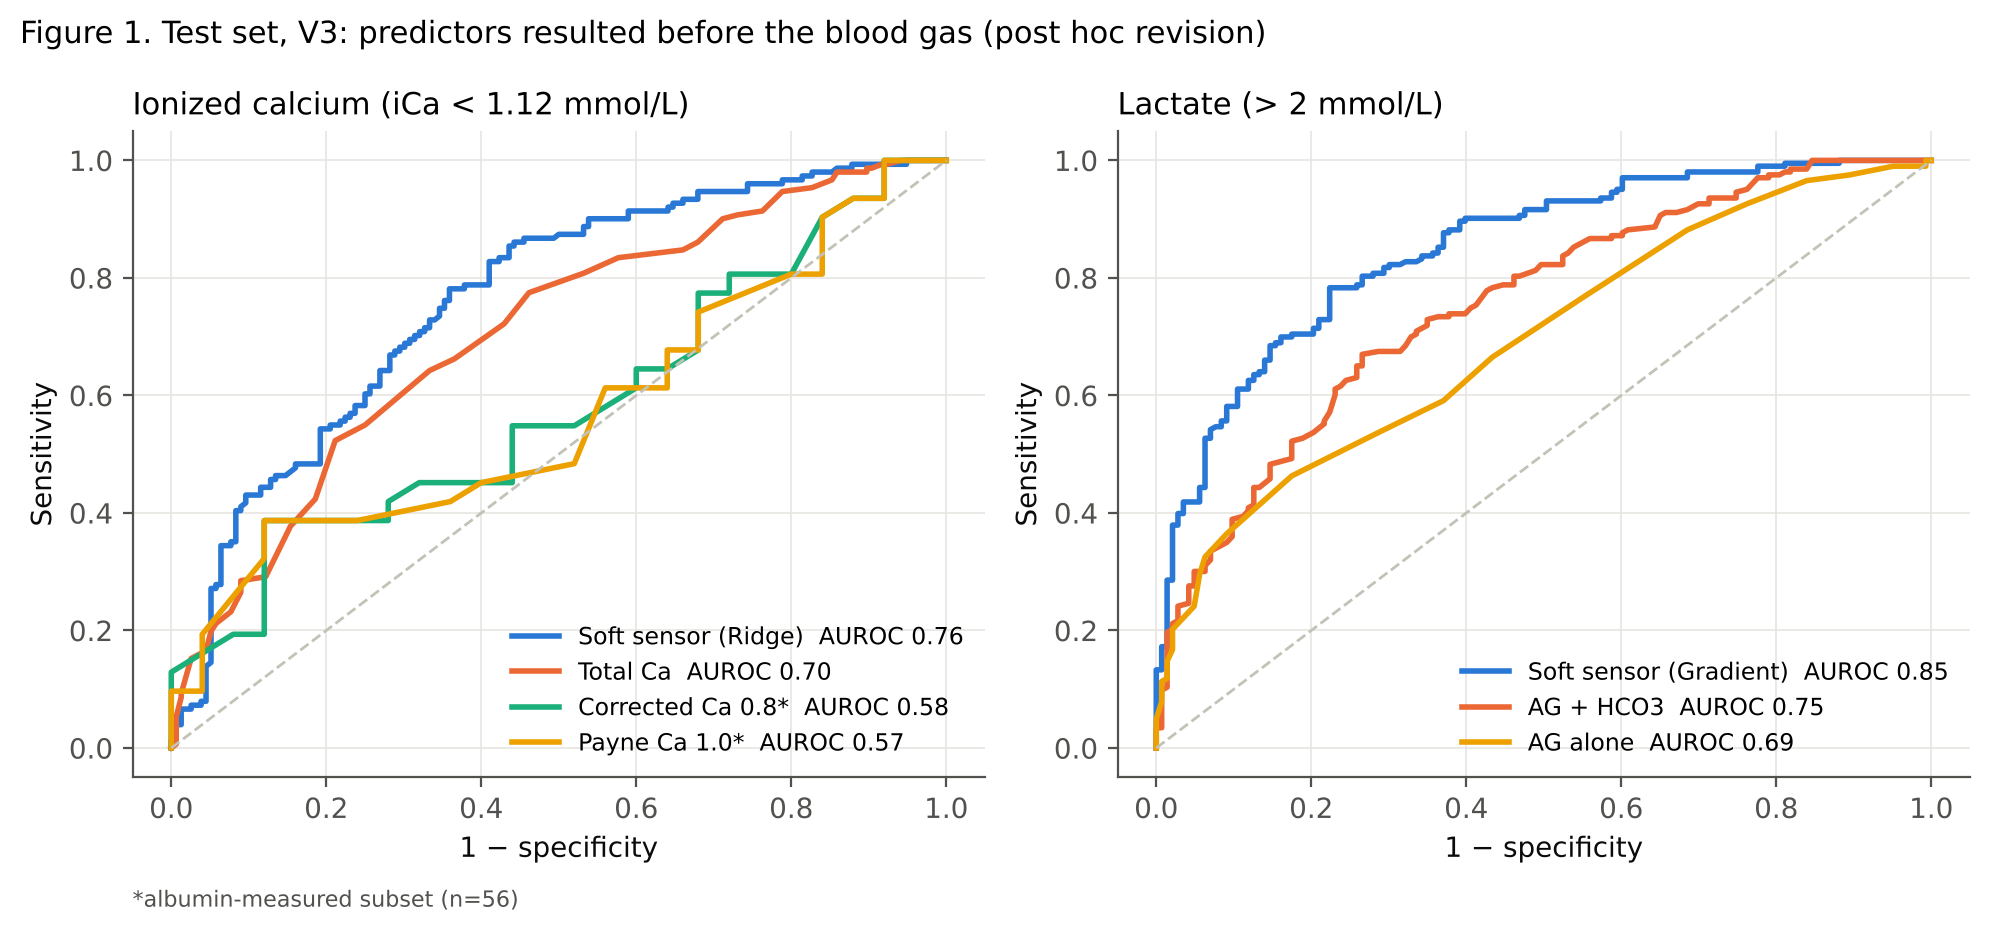

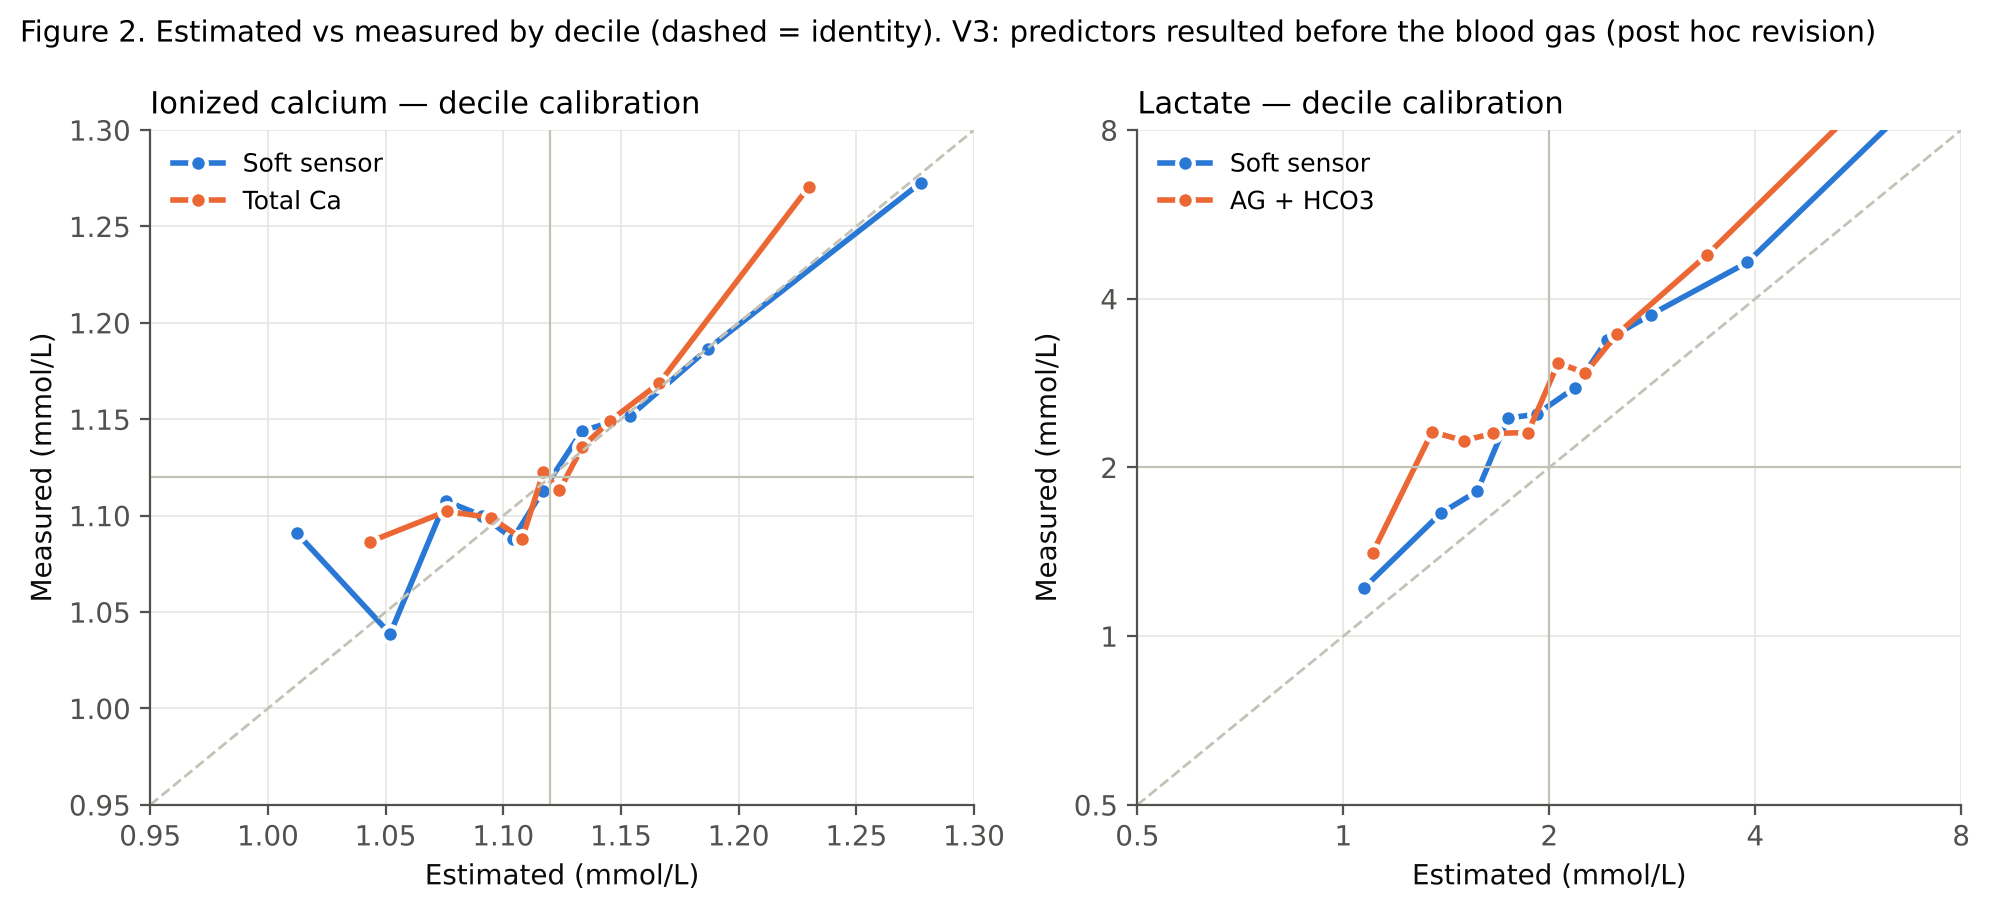

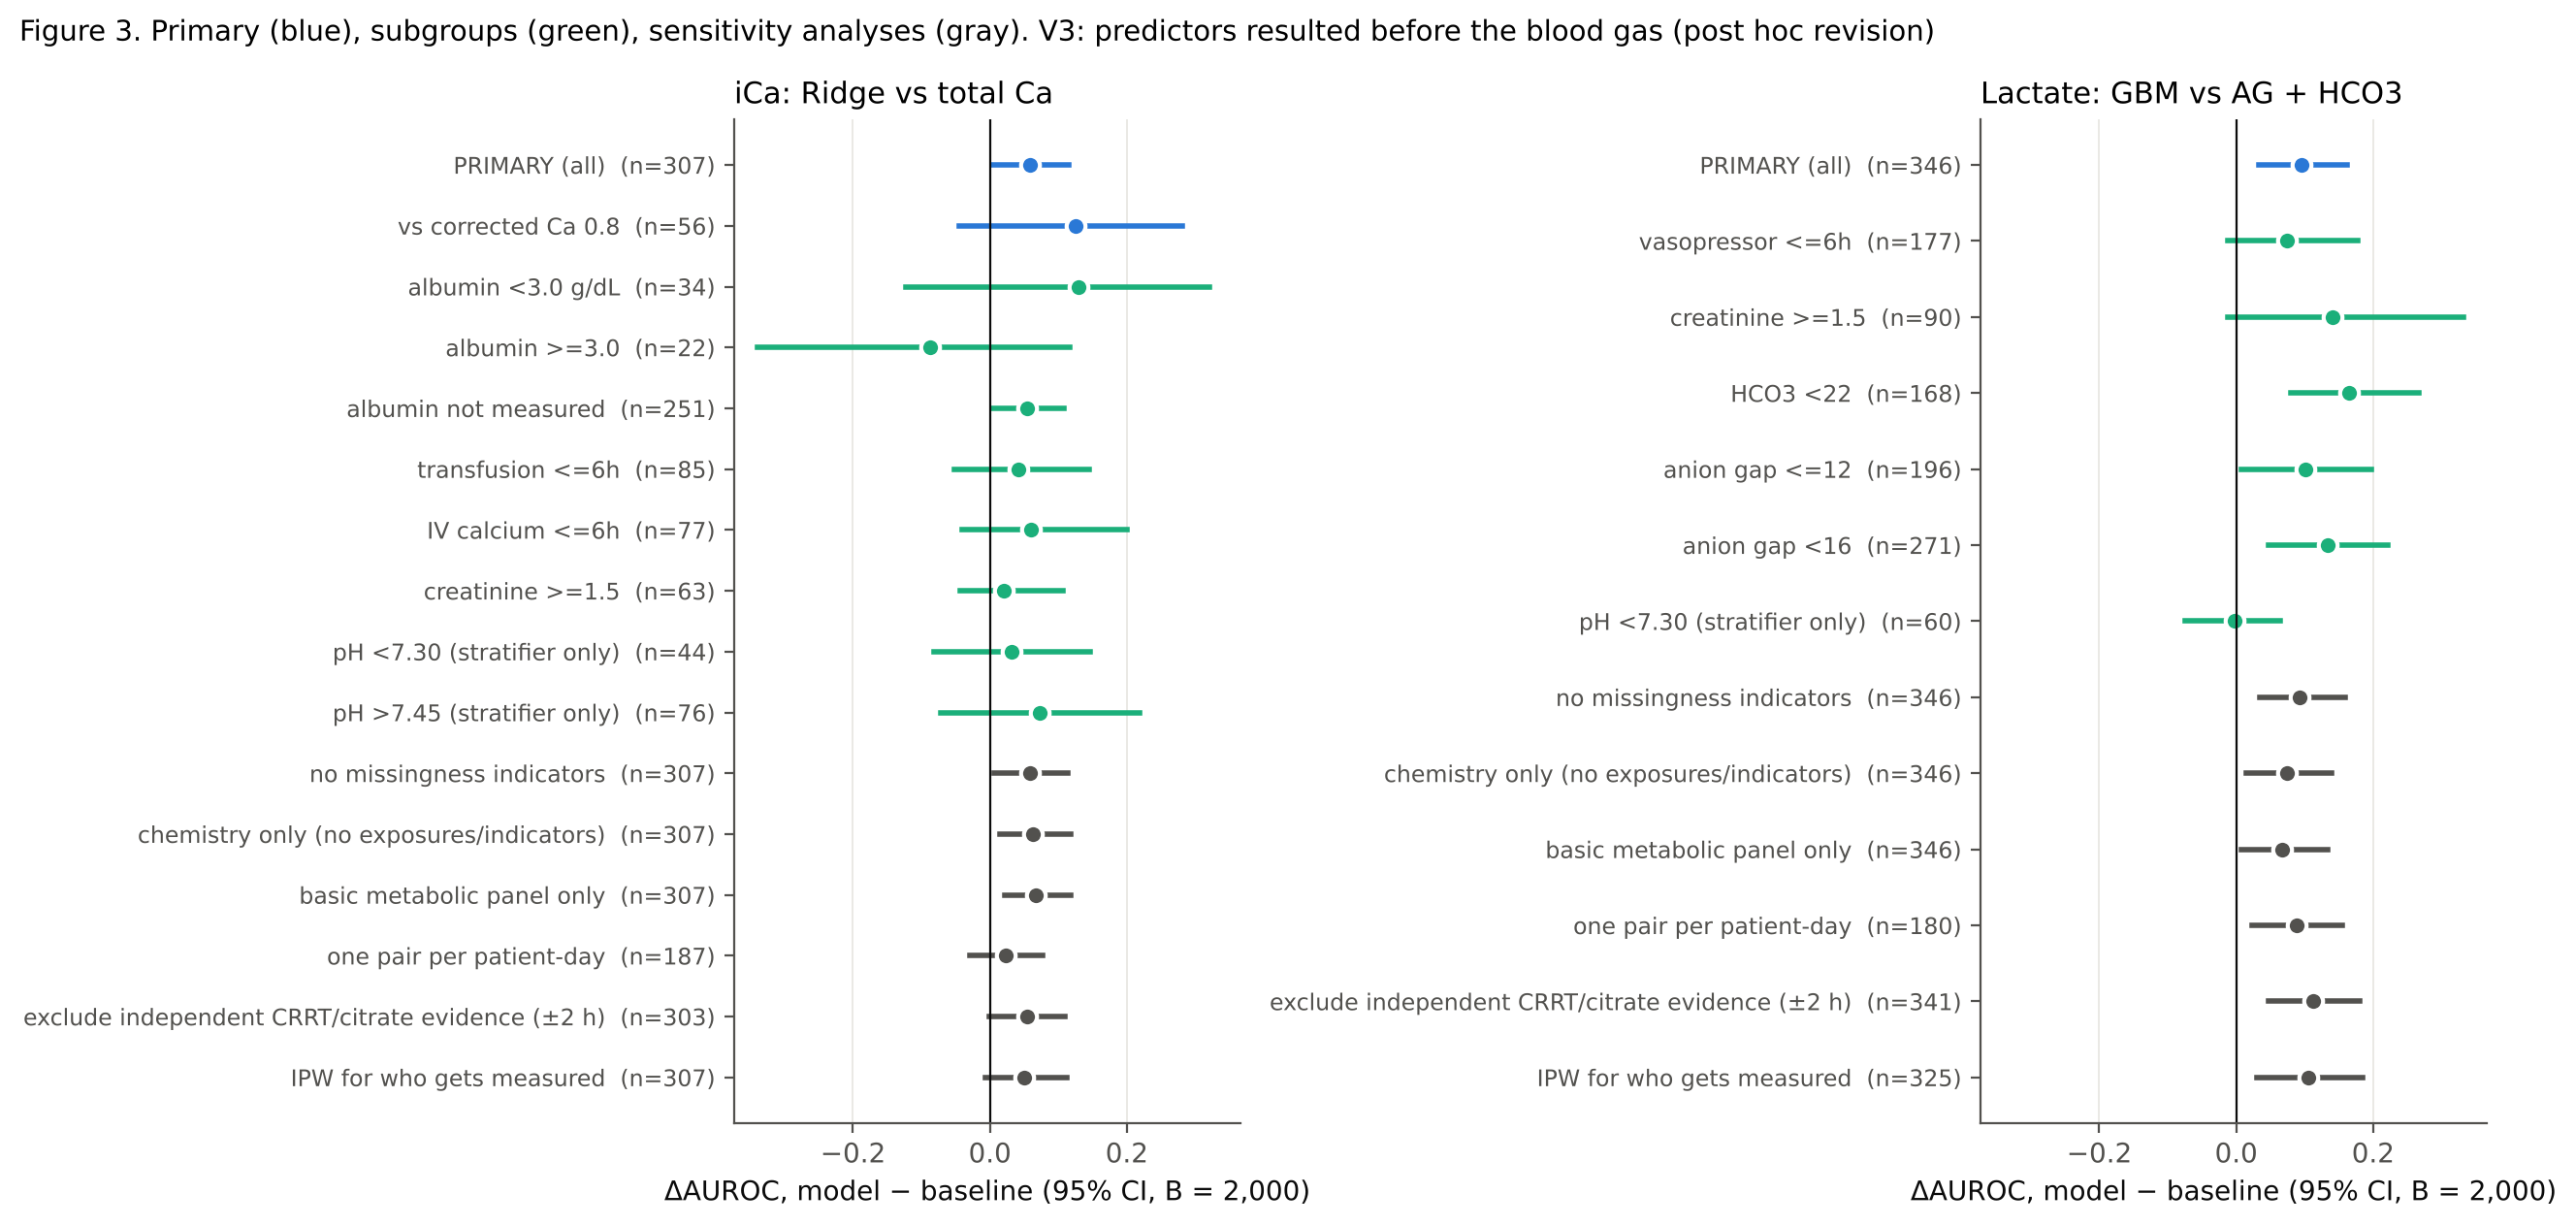

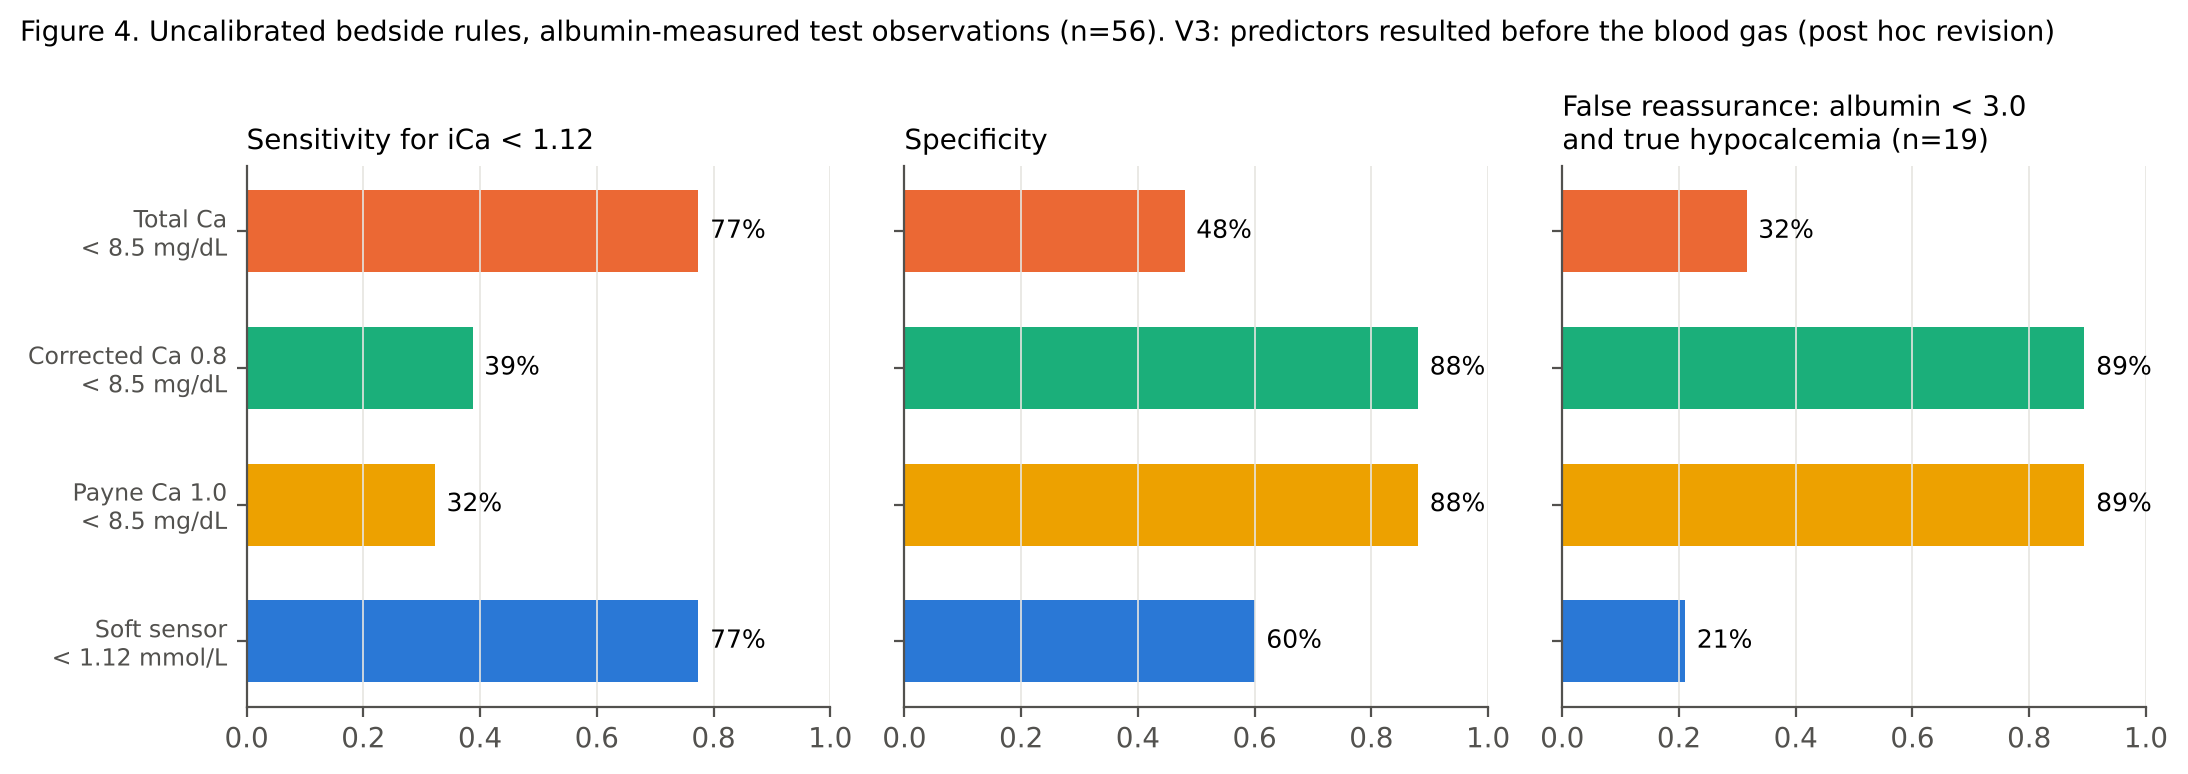

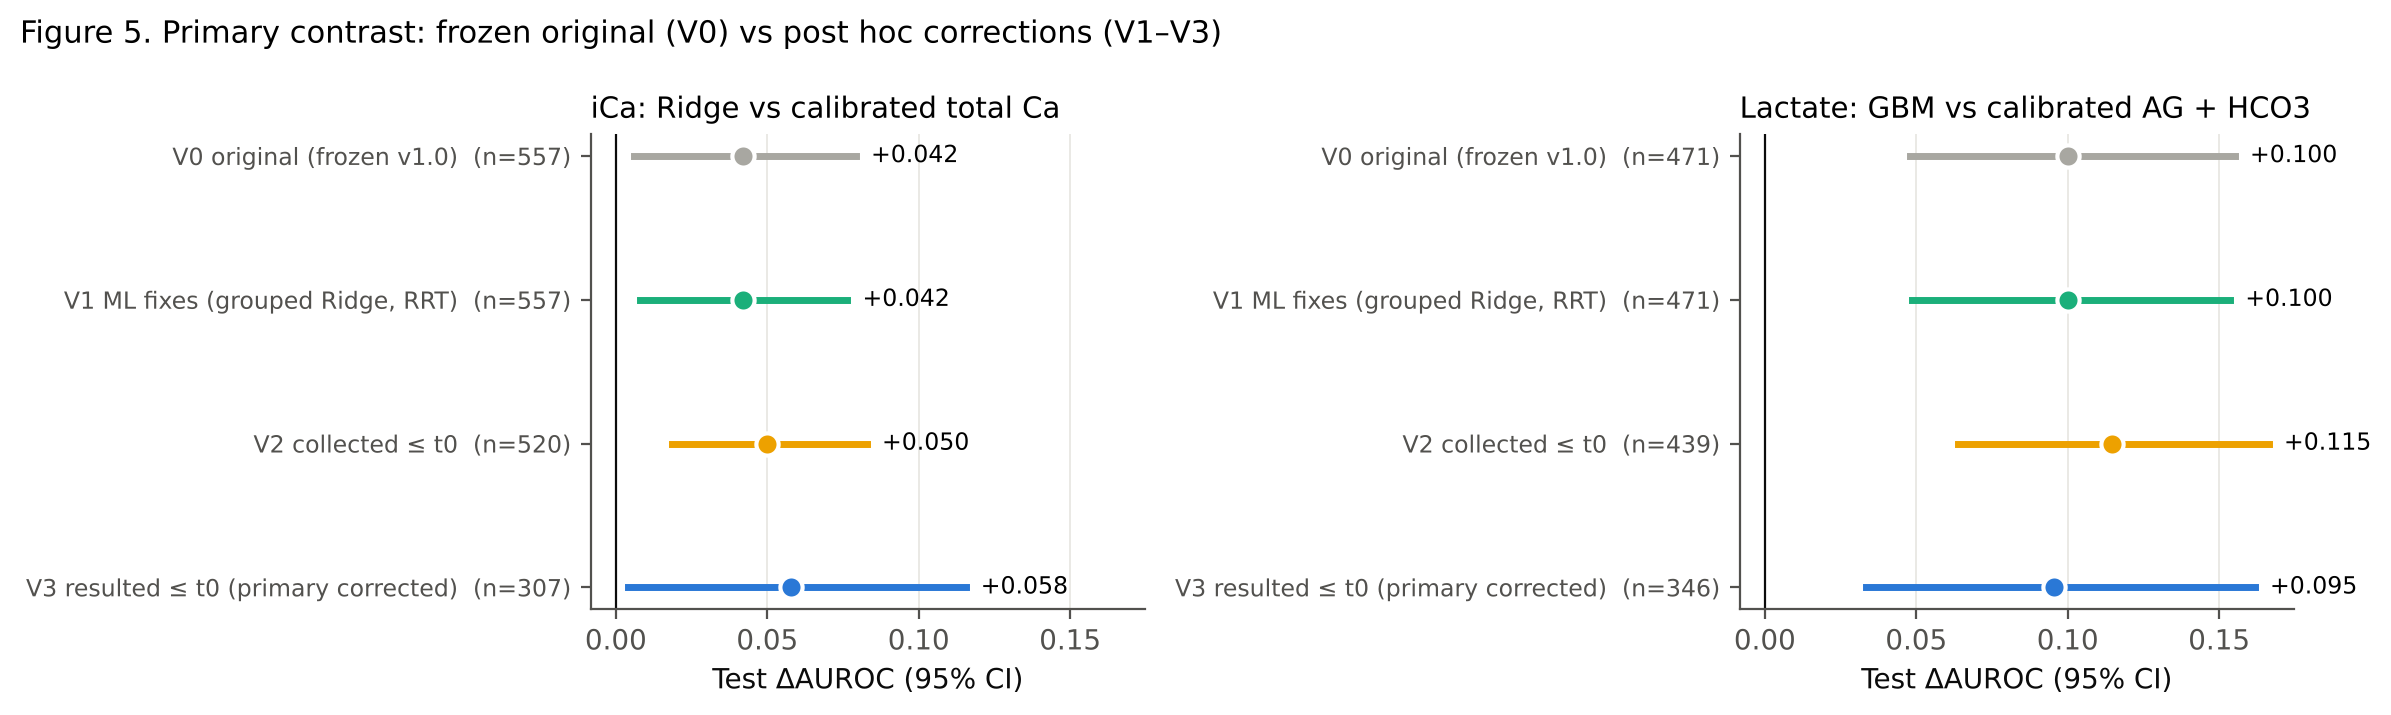

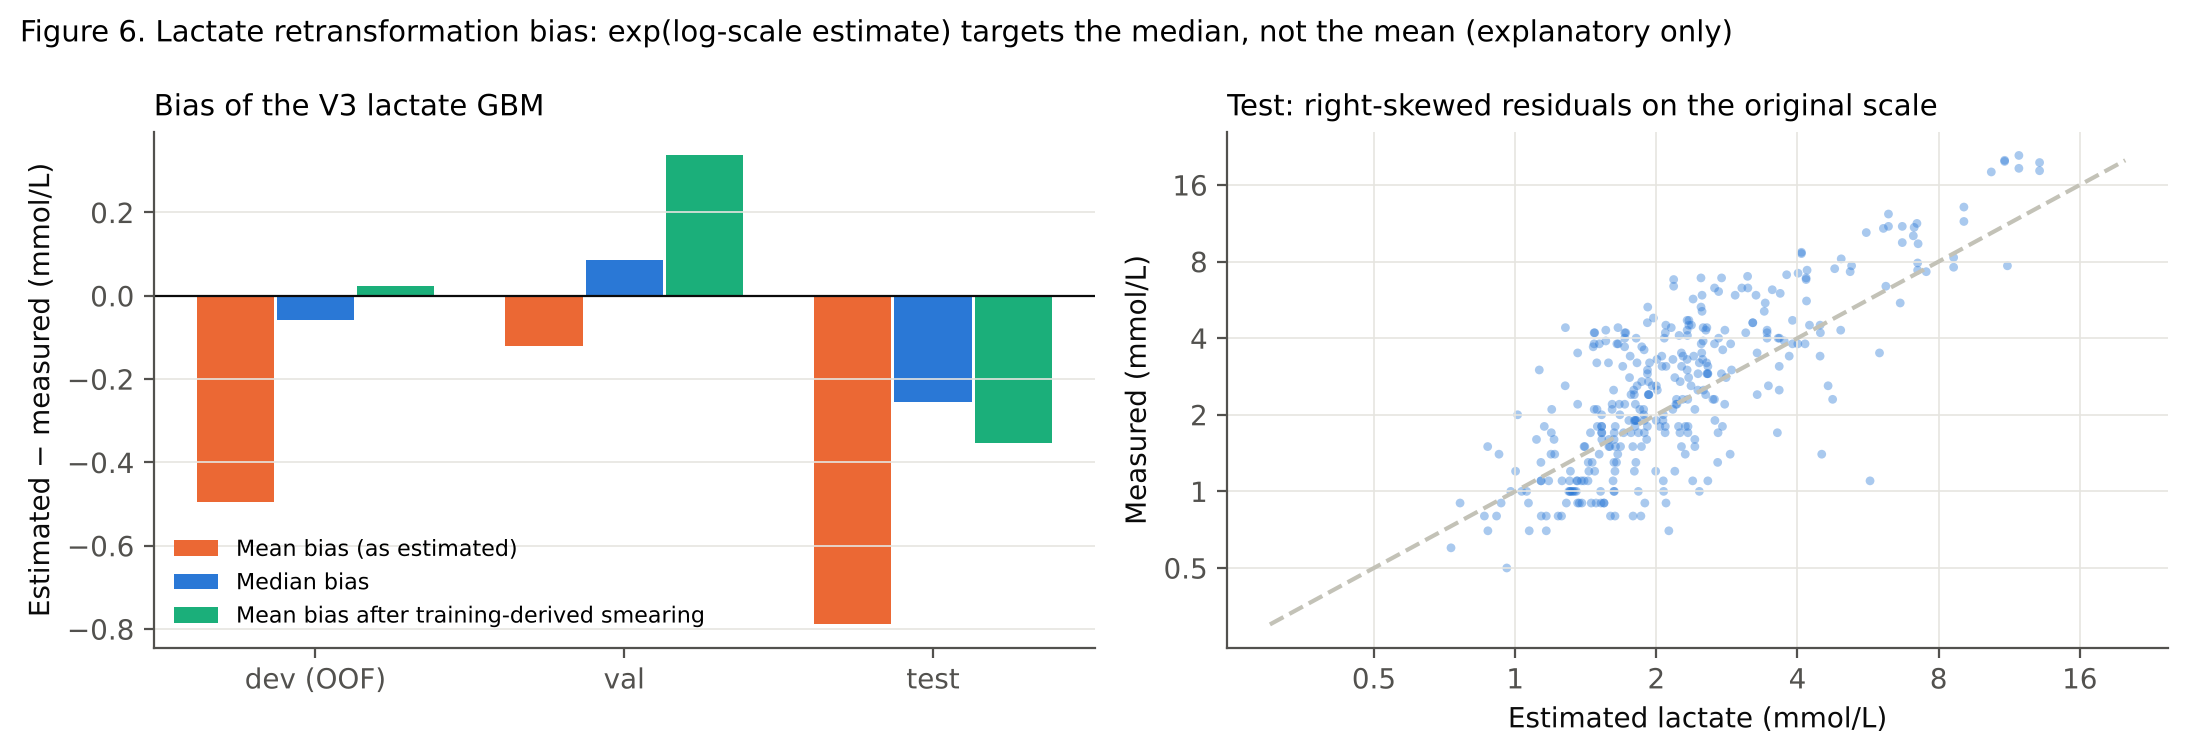

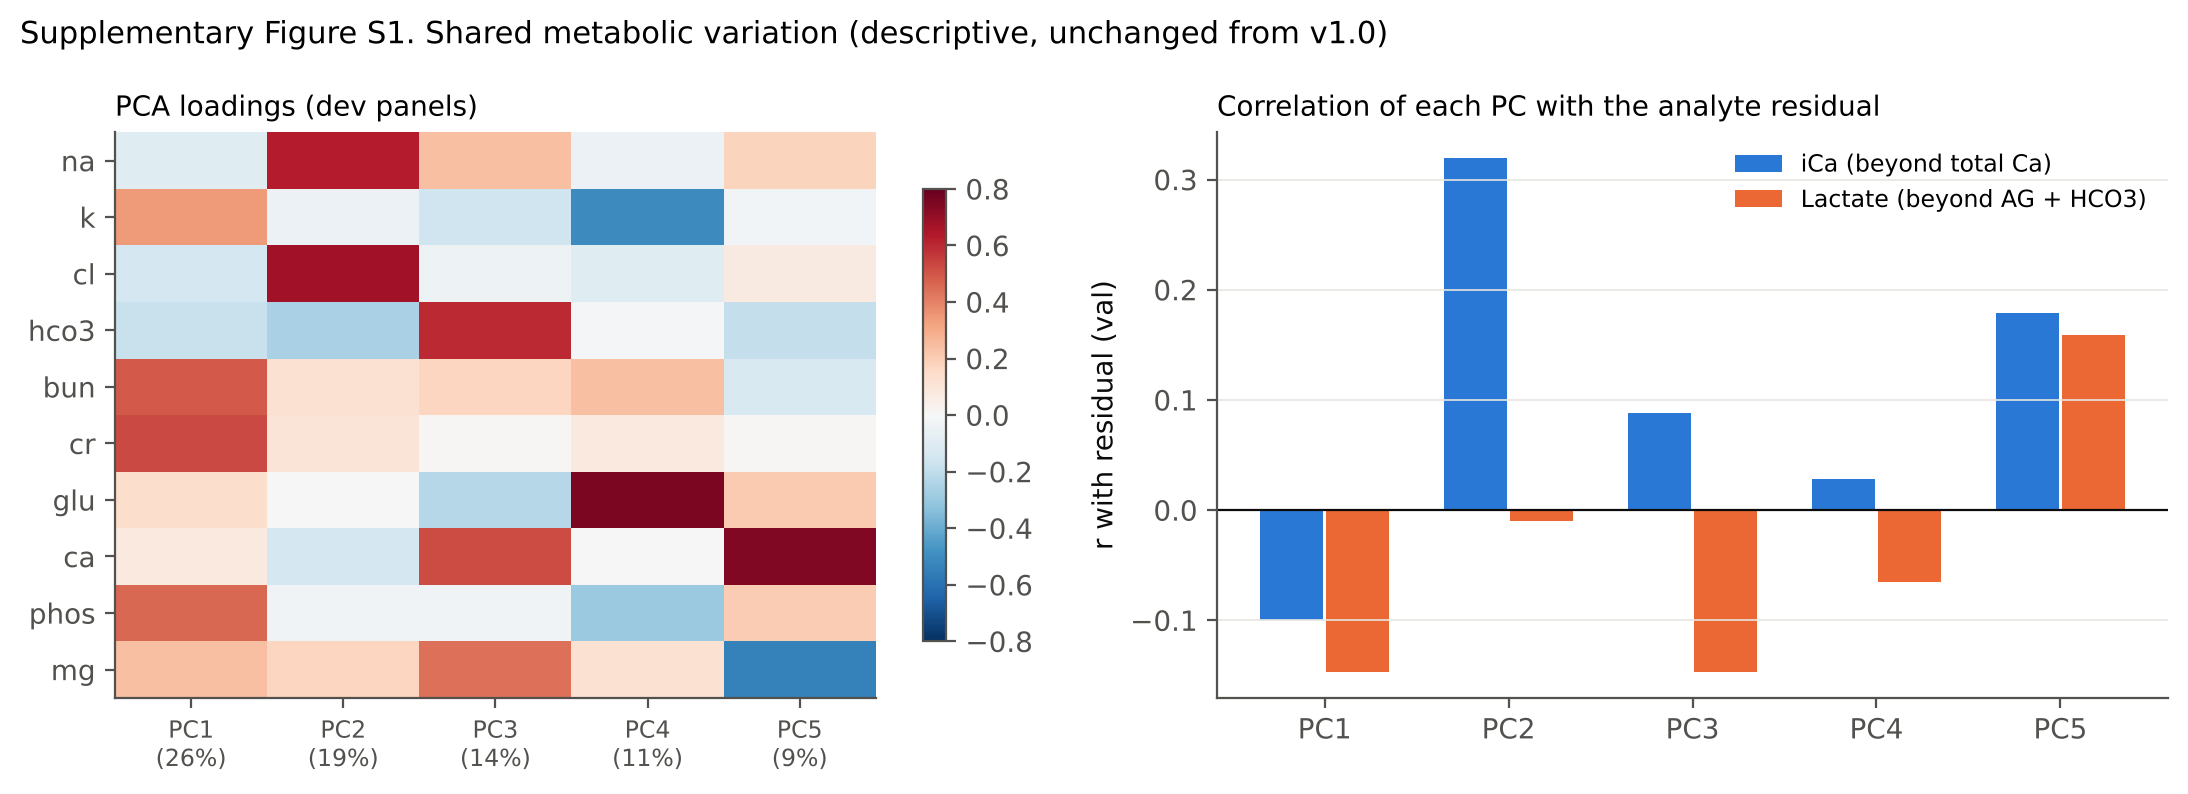

[PASS] Figure 1 AUROC equals table (ica, Ridge regression)  0.7626
[PASS] Figure 1 AUROC equals table (ica, B1 total Ca (calibrated))  0.7047
[PASS] Figure 1 AUROC equals table (ica, B2 albumin-corrected Ca, 0.8 (calibrated))  0.5806
[PASS] Figure 1 AUROC equals table (ica, B3 Payne-corrected Ca, 1.0 (calibrated))  0.5703
[PASS] Figure 1 AUROC equals table (lact, Gradient boosting)  0.8498
[PASS] Figure 1 AUROC equals table (lact, B2 anion gap + HCO3 (calibrated))  0.7544
[PASS] Figure 1 AUROC equals table (lact, B1 anion gap (calibrated))  0.6947
[PASS] Figure 5 values equal the comparison table  drawn directly from CMP


In [14]:
import matplotlib; import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from matplotlib.ticker import FixedLocator, NullLocator, FormatStrFormatter
%matplotlib inline
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#52514e','axes.labelcolor':'#0b0b0b',
  'xtick.color':'#52514e','ytick.color':'#52514e','axes.grid':True,'grid.color':'#e6e5e0','grid.linewidth':0.6,'figure.facecolor':'white','axes.facecolor':'white','savefig.dpi':300,'pdf.fonttype':42})
Cc = {'model':'#2a78d6','base':'#eb6834','corr':'#1baf7a','payne':'#eda100','ink':'#0b0b0b','muted':'#52514e','grey':'#a8a7a1'}
S = {'ica': dict(title='Ionized calcium (iCa < 1.12 mmol/L)', b=[('B1 total Ca (calibrated)','Total Ca',Cc['base']),('B2 albumin-corrected Ca, 0.8 (calibrated)','Corrected Ca 0.8*',Cc['corr']),('B3 Payne-corrected Ca, 1.0 (calibrated)','Payne Ca 1.0*',Cc['payne'])], sgn=-1),
     'lact': dict(title='Lactate (> 2 mmol/L)', b=[('B2 anion gap + HCO3 (calibrated)','AG + HCO3',Cc['base']),('B1 anion gap (calibrated)','AG alone',Cc['payne'])], sgn=1)}
PRED = {an: pd.DataFrame({**TEST[an]['pred'], 'y': TEST[an]['data'][an].values}) for an in ['ica','lact']}
TAG = 'V3: predictors resulted before the blood gas (post hoc revision)'
def save(fig, name): fig.savefig(FIG/f'{name}.png', bbox_inches='tight'); fig.savefig(FIG/f'{name}.pdf', bbox_inches='tight'); plt.show(); plt.close(fig)
FIGAUC = {}
fig, ax = plt.subplots(1, 2, figsize=(10, 4.8))
for a, an in zip(ax, ['ica','lact']):
    Pp = PRED[an]; s = S[an]; t = pos(an, Pp.y.values)
    for k, lab, col in [(PRIM[an], 'Soft sensor ('+PRIM[an].split(' ')[0]+')', Cc['model'])] + s['b']:
        m = ~Pp[k].isna().values; fpr, tpr, _ = roc_curve(t[m], s['sgn']*Pp[k].values[m]); FIGAUC[(an, k)] = roc_auc_score(t[m], s['sgn']*Pp[k].values[m])
        a.plot(fpr, tpr, color=col, lw=2, label=f'{lab}  AUROC {FIGAUC[(an, k)]:.2f}')
    a.plot([0,1], [0,1], color='#c3c2b7', lw=1, ls='--'); a.set_title(s['title'], loc='left', fontsize=11); a.set_xlabel('1 − specificity'); a.set_ylabel('Sensitivity'); a.legend(frameon=False, fontsize=8.5, loc='lower right')
ax[0].text(0, -0.2, '*albumin-measured subset (n=%d)' % int(PRED['ica']['B2 albumin-corrected Ca, 0.8 (calibrated)'].notna().sum()), transform=ax[0].transAxes, fontsize=8, color=Cc['muted'])
fig.suptitle('Figure 1. Test set, ' + TAG, x=0.01, ha='left', fontsize=11); fig.tight_layout(); save(fig, 'fig1_roc_V3')

fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
for a, an in zip(ax, ['ica','lact']):
    Pp = PRED[an]
    for k, lab, col in [(PRIM[an], 'Soft sensor', Cc['model']), (S[an]['b'][0][0], S[an]['b'][0][1], Cc['base'])]:
        d = pd.DataFrame({'p': Pp[k], 'y': Pp.y}).dropna(); d['bin'] = pd.qcut(d.p, 10, labels=False, duplicates='drop'); gg = d.groupby('bin').mean()
        a.plot(gg.p, gg.y, '-o', color=col, lw=2, ms=6, label=lab, markeredgecolor='white', markeredgewidth=1.5)
    lo, hi = (0.95, 1.3) if an=='ica' else (0.5, 8); a.plot([lo,hi], [lo,hi], color='#c3c2b7', ls='--', lw=1); a.set_xlim(lo, hi); a.set_ylim(lo, hi)
    if an == 'lact':
        a.set_xscale('log'); a.set_yscale('log')
        for ax_ in (a.xaxis, a.yaxis): ax_.set_major_locator(FixedLocator([0.5,1,2,4,8])); ax_.set_minor_locator(NullLocator()); ax_.set_major_formatter(FormatStrFormatter('%g'))
    th = 1.12 if an=='ica' else 2; a.axhline(th, color='#c3c2b7', lw=0.8); a.axvline(th, color='#c3c2b7', lw=0.8)
    a.set_title(S[an]['title'].split(' (')[0]+' — decile calibration', loc='left', fontsize=11); a.set_xlabel('Estimated (mmol/L)'); a.set_ylabel('Measured (mmol/L)'); a.legend(frameon=False, fontsize=9, loc='upper left')
fig.suptitle('Figure 2. Estimated vs measured by decile (dashed = identity). ' + TAG, x=0.01, ha='left', fontsize=10.5); fig.tight_layout(); save(fig, 'fig2_calibration_V3')

R3 = SEC[(SEC.variant=='V3') & SEC.analysis.isin(['PRIMARY','KEY SECONDARY vs corrected Ca 0.8 (albumin-measured)','subgroup','sensitivity']) & SEC.dAUC.notna()]
fig, ax = plt.subplots(1, 2, figsize=(13, 6.4), sharex=True)
for a, an in zip(ax, ['ica','lact']):
    d = R3[R3.analyte==an].reset_index(drop=True); yy = np.arange(len(d))[::-1]
    lab = [('PRIMARY (all)' if r.analysis=='PRIMARY' else ('vs corrected Ca 0.8' if 'KEY' in r.analysis else r.stratum)) + f'  (n={int(r.n)})' for r in d.itertuples()]
    for i, r in enumerate(d.itertuples()):
        col = Cc['model'] if (r.analysis=='PRIMARY' or 'KEY' in r.analysis) else (Cc['muted'] if r.analysis=='sensitivity' else Cc['corr'])
        a.plot([r.dAUC_lo, r.dAUC_hi], [yy[i]]*2, color=col, lw=2); a.plot(r.dAUC, yy[i], 'o', color=col, ms=7, markeredgecolor='white', markeredgewidth=1.5)
    a.axvline(0, color=Cc['ink'], lw=0.8); a.set_yticks(yy); a.set_yticklabels(lab, fontsize=8.5); a.grid(axis='y', visible=False)
    a.set_title('iCa: Ridge vs total Ca' if an=='ica' else 'Lactate: GBM vs AG + HCO3', loc='left', fontsize=11); a.set_xlabel('ΔAUROC, model − baseline (95% CI, B = 2,000)')
fig.suptitle('Figure 3. Primary (blue), subgroups (green), sensitivity analyses (gray). ' + TAG, x=0.01, ha='left', fontsize=10.5); fig.tight_layout(); save(fig, 'fig3_forest_V3')

Bt = SEC[(SEC.variant=='V3') & SEC.analysis.str.startswith('bedside')].set_index('stratum').loc[['total Ca <8.5 mg/dL','corrected 0.8 <8.5 mg/dL','Payne 1.0 <8.5 mg/dL','primary model <1.12 mmol/L']]
labs4 = ['Total Ca\n< 8.5 mg/dL','Corrected Ca 0.8\n< 8.5 mg/dL','Payne Ca 1.0\n< 8.5 mg/dL','Soft sensor\n< 1.12 mmol/L']; cols4 = [Cc['base'], Cc['corr'], Cc['payne'], Cc['model']]
fig, ax = plt.subplots(1, 3, figsize=(11, 3.9))
for a, (col, tt) in zip(ax, [('sens','Sensitivity for iCa < 1.12'), ('spec','Specificity'), ('false_reassurance_lowalb', f'False reassurance: albumin < 3.0\nand true hypocalcemia (n={int(Bt.n_hypo_lowalb.iloc[0])})')]):
    vv = Bt[col].values; a.barh(range(4)[::-1], vv, color=cols4, height=0.6); a.set_xlim(0, 1)
    for i, x in enumerate(vv): a.text(x+0.02, 3-i, f'{x:.0%}', va='center', fontsize=9)
    a.set_yticks(range(4)[::-1]); a.set_yticklabels(labs4 if a is ax[0] else ['']*4, fontsize=8.5); a.set_title(tt, loc='left', fontsize=10); a.grid(axis='y', visible=False)
fig.suptitle(f'Figure 4. Uncalibrated bedside rules, albumin-measured test observations (n={int(Bt.n.iloc[0])}). ' + TAG, x=0.01, ha='left', fontsize=10); fig.tight_layout(); save(fig, 'fig4_bedside_rules_V3')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True); vc = [Cc['grey'], Cc['corr'], Cc['payne'], Cc['model']]
for a, an in zip(ax, ['ica','lact']):
    d = CMP[CMP.analyte==an].reset_index(drop=True); yy = np.arange(len(d))[::-1]
    for i, r in d.iterrows():
        a.plot([r.dAUROC_lo, r.dAUROC_hi], [yy[i]]*2, color=vc[i], lw=2.5); a.plot(r.dAUROC, yy[i], 'o', color=vc[i], ms=8, markeredgecolor='white', markeredgewidth=1.5)
        a.text(r.dAUROC_hi + 0.005, yy[i], f'{r.dAUROC:+.3f}', va='center', fontsize=8.5)
    a.set_yticks(yy); a.set_yticklabels([f"{t}  (n={n})" for t, n in zip(d.variant, d.n)], fontsize=8.5); a.axvline(0, color=Cc['ink'], lw=0.8); a.grid(axis='y', visible=False)
    a.set_title('iCa: Ridge vs calibrated total Ca' if an=='ica' else 'Lactate: GBM vs calibrated AG + HCO3', loc='left', fontsize=10.5); a.set_xlabel('Test ΔAUROC (95% CI)')
fig.suptitle('Figure 5. Primary contrast: frozen original (V0) vs post hoc corrections (V1–V3)', x=0.01, ha='left', fontsize=11); fig.tight_layout(); save(fig, 'fig5_original_vs_corrected')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); xb = np.arange(len(BIAS))
for j, (col, lab, cc) in enumerate([('mean_bias','Mean bias (as estimated)',Cc['base']), ('median_bias','Median bias',Cc['model']), ('mean_bias_if_smeared','Mean bias after training-derived smearing',Cc['corr'])]):
    ax[0].bar(xb + (j-1)*0.26, BIAS[col], width=0.25, color=cc, label=lab)
ax[0].axhline(0, color=Cc['ink'], lw=0.8); ax[0].set_xticks(xb); ax[0].set_xticklabels(BIAS.split); ax[0].set_ylabel('Estimated − measured (mmol/L)'); ax[0].legend(frameon=False, fontsize=8); ax[0].grid(axis='x', visible=False)
ax[0].set_title('Bias of the V3 lactate GBM', loc='left', fontsize=10.5)
yt, pt = PRED['lact'].y.values, PRED['lact'][PRIM['lact']].values
ax[1].scatter(pt, yt, s=10, alpha=0.4, color=Cc['model'], edgecolor='none'); ax[1].plot([0.3, 20], [0.3, 20], ls='--', color='#c3c2b7'); ax[1].set_xscale('log'); ax[1].set_yscale('log')
for ax_ in (ax[1].xaxis, ax[1].yaxis): ax_.set_major_locator(FixedLocator([0.5,1,2,4,8,16])); ax_.set_minor_locator(NullLocator()); ax_.set_major_formatter(FormatStrFormatter('%g'))
ax[1].set_xlabel('Estimated lactate (mmol/L)'); ax[1].set_ylabel('Measured (mmol/L)'); ax[1].set_title('Test: right-skewed residuals on the original scale', loc='left', fontsize=10.5)
fig.suptitle('Figure 6. Lactate retransformation bias: exp(log-scale estimate) targets the median, not the mean (explanatory only)', x=0.01, ha='left', fontsize=10.5); fig.tight_layout(); save(fig, 'fig6_lactate_bias')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(PCA_LOAD.values, cmap='RdBu_r', vmin=-0.8, vmax=0.8, aspect='auto'); ax[0].set_xticks(range(5)); ax[0].set_xticklabels([f'{p}\n({v:.0%})' for p, v in PCA_VAR.items()], fontsize=8.5)
ax[0].set_yticks(range(len(CORE))); ax[0].set_yticklabels(CORE); ax[0].grid(False); ax[0].set_title('PCA loadings (dev panels)', loc='left', fontsize=10); fig.colorbar(im, ax=ax[0], shrink=0.8)
for i, (an, col) in enumerate([('ica', Cc['model']), ('lact', Cc['base'])]):
    d = PCA_ASSOC[(PCA_ASSOC.analyte==an) & (PCA_ASSOC.split=='val')]
    ax[1].bar(np.arange(5) + (i-0.5)*0.36, d.r_with_residual_beyond_baseline, width=0.34, color=col, label='iCa (beyond total Ca)' if an=='ica' else 'Lactate (beyond AG + HCO3)')
ax[1].axhline(0, color=Cc['ink'], lw=0.8); ax[1].set_xticks(range(5)); ax[1].set_xticklabels(PCA_LOAD.columns); ax[1].set_ylabel('r with residual (val)'); ax[1].legend(frameon=False, fontsize=8.5); ax[1].grid(axis='x', visible=False)
ax[1].set_title('Correlation of each PC with the analyte residual', loc='left', fontsize=10)
fig.suptitle('Supplementary Figure S1. Shared metabolic variation (descriptive, unchanged from v1.0)', x=0.01, ha='left', fontsize=11); fig.tight_layout(); save(fig, 'figS1_pca')
for (an, k), vv in FIGAUC.items():
    tv = TEST[an]['models'].set_index('model').AUROC.get(k, np.nan)
    if not np.isnan(tv): check(f'Figure 1 AUROC equals table ({an}, {k})', abs(vv - tv) < 1e-12, f'{vv:.4f}')
check('Figure 5 values equal the comparison table', True, 'drawn directly from CMP')

## 12. Results workbook and key numbers
- **Workbook:** `results/VML_results_v1.1.xlsx`, aggregate numbers only.
- **Key numbers:** `results/key_numbers_v1.1.json`. The written report is checked against this file.

In [15]:
def fmt(r, m): return f"{r[m]:.3f} ({r[m+'_lo']:.3f}–{r[m+'_hi']:.3f})"
T1 = pd.concat([TEST[an]['models'].assign(task='iCa < 1.12 mmol/L' if an=='ica' else 'Lactate > 2 mmol/L') for an in ['ica','lact']])
T1 = pd.DataFrame([{'Task': r.task, 'Estimator': r.model, 'n': int(r.n), 'Prevalence': round(r.prev,3), 'MAE (mmol/L)': fmt(r, 'MAE') if pd.notna(r.MAE) else '-', 'Bias': round(r.bias,3) if pd.notna(r.bias) else '-',
                    'AUROC': fmt(r, 'AUROC'), 'AUPRC': fmt(r, 'AUPRC'), 'Sensitivity': fmt(r, 'sens'), 'Specificity': fmt(r, 'spec')} for _, r in T1.iterrows()])
readme = pd.DataFrame({'Sheet': ['T0_original_vs_corrected','T1_V3_test_all_models','T2_V3_contrasts','T3_V3_bedside_rules','T4_V3_subgroups_sensitivity','V1_V2_V3_primary',
    'V3_test_deltas','V3_devval_models','V3_devval_deltas','V3_perm_importance','pairing_flow','timing_audit','lab_turnaround','treatment_charting_lag','units','missingness',
    'ridge_alpha_check','model_tuning_audit','lactate_bias','PCA','rules_concurrent','rules_sequential','rrt_verification','qa_checks'],
  'Contents': ['Primary contrast: frozen V0 vs V1 (ML fixes), V2 (collected ≤ t0), V3 (resulted ≤ t0, primary corrected)', 'All estimators on the test set, V3, 95% CI (B=2,000)',
    'Primary, key secondary and corrected-Ca contrasts, V3', 'Uncalibrated bedside rules, V3', 'Subgroups, severe lactate, AG<16, sensitivity analyses, V3 (B=2,000)', 'Primary contrasts for V1–V3',
    'All pairwise contrasts on the test set, V3', 'Dev grouped-CV and val, V3 (B=2,000)', 'Dev/val contrasts, V3', 'Permutation importance of the V3 primary models (test)',
    'References, pairs, RRT exclusions and chemistry age per variant', 'Share of predictors collected/resulted after t0 per variant', 'Lab turnaround (storetime − charttime) and reliability',
    'inputevents charting lag (not used for exposure)', 'Units per analyte from labevents.valueuom', 'Missingness and imputation per predictor', 'Ridge alpha: row-LOO (v1.0) vs patient-grouped (v1.1)',
    'Internal validation per model', 'Lactate retransformation bias and training-derived smearing (explanatory only)', 'PCA loadings and PC–residual correlations (descriptive)',
    'Concurrent association rules (dev→val), associations only', 'Sequential rules with corrected labels', 'Active-RRT exclusion vs independent CRRT/citrate evidence (±2 h), dev+val, before exclusion', 'Programmatic QA checks']})
for an in ['ica','lact']: TEST[an]['deltas']['analyte'] = an
with pd.ExcelWriter(RES/'VML_results_v1.1.xlsx', engine='xlsxwriter') as xw:
    sheets = {'README': readme, 'T0_original_vs_corrected': CMP, 'T1_V3_test_all_models': T1,
              'T2_V3_contrasts': SEC[(SEC.variant=='V3') & SEC.analysis.str.contains('PRIMARY|SECONDARY|secondary')].dropna(axis=1, how='all'),
              'T3_V3_bedside_rules': SEC[(SEC.variant=='V3') & SEC.analysis.str.startswith('bedside')].dropna(axis=1, how='all'),
              'T4_V3_subgroups_sensitivity': SEC[(SEC.variant=='V3') & ~SEC.analysis.str.contains('PRIMARY|SECONDARY|secondary|bedside')].dropna(axis=1, how='all'),
              'V1_V2_V3_primary': SEC[SEC.analysis=='PRIMARY'], 'V3_test_deltas': pd.concat([TEST[a]['deltas'] for a in TEST]),
              'V3_devval_models': pd.concat([DEV[a][k].assign(analyte=a, split=k.split('_')[0]) for a in DEV for k in ['dev_models','val_models']]),
              'V3_devval_deltas': pd.concat([DEV[a][k].assign(analyte=a, split=k.split('_')[0]) for a in DEV for k in ['dev_deltas','val_deltas']]),
              'V3_perm_importance': pd.concat([PERM[a].assign(analyte=a) for a in PERM]), 'pairing_flow': FLOW, 'timing_audit': TIMING, 'lab_turnaround': TAT,
              'treatment_charting_lag': LAG.reset_index(), 'units': UNITS, 'missingness': MISS, 'ridge_alpha_check': ALPHA, 'model_tuning_audit': TUNING, 'lactate_bias': BIAS,
              'PCA': pd.concat([PCA_LOAD.reset_index().rename(columns={'index':'row'}), pd.DataFrame([{'row':'explained variance', **PCA_VAR.round(3).to_dict()}]), PCA_ASSOC.rename(columns={'analyte':'row'})]),
              'rules_concurrent': RULES_C, 'rules_sequential': RULES_S, 'rrt_verification': RRTV, 'qa_checks': pd.DataFrame(QA)}
    for name, df in sheets.items():
        df.to_excel(xw, sheet_name=name[:31], index=False); ws = xw.sheets[name[:31]]; ws.freeze_panes(1, 0); ws.set_column(0, 0, 40); ws.set_column(1, max(1, df.shape[1]-1), 15)
s3 = SEC[SEC.variant=='V3'].set_index(['analyte','analysis','stratum'])
KEY = {'V3_n': {an: int(CMP[(CMP.analyte==an) & CMP.variant.str.startswith('V3')].n.iloc[0]) for an in ['ica','lact']},
       'CMP': CMP[['variant','analyte','n','AUROC_model','AUROC_baseline','dAUROC','dAUROC_lo','dAUROC_hi','MAE_model','MAE_baseline','MAE_red_lo','MAE_red_hi']].round(4).to_dict('records'),
       'V3_bedside': SEC[(SEC.variant=='V3') & SEC.analysis.str.startswith('bedside')][['stratum','sens','spec','false_reassurance_lowalb','n_hypo_lowalb']].round(3).to_dict('records'),
       'V3_secondary': SEC[(SEC.variant=='V3') & SEC.analysis.str.contains('SECONDARY|secondary')][['analysis','n','dAUC','dAUC_lo','dAUC_hi']].round(3).to_dict('records'),
       'V3_AG16': s3.loc[('lact','hyperlactatemia when AG<16','AG<16'), ['n','npos','model_sens','model_spec']].astype(float).round(3).to_dict(),
       'alpha': {f'{k[0]}_{k[1]}': float(v) for k, v in ALPHA_FINAL.items() if k[1]=='ica'}, 'bias': BIAS.round(3).to_dict('records')}
json.dump(KEY, open(RES/'key_numbers_v1.1.json', 'w'), indent=1, default=float)
print('wrote', RES/'VML_results_v1.1.xlsx', 'and key_numbers_v1.1.json')

wrote /home/claude/COSC5610_VML_v1.1/results/VML_results_v1.1.xlsx and key_numbers_v1.1.json


## 13. QA summary
Every check is logged in the workbook sheet `qa_checks`. Interpretation and remaining limitations are in `docs/QA_REPORT_v1.1.md`.

In [16]:
qa = pd.DataFrame(QA); display(qa.result.value_counts()); qa

result
PASS    29
Name: count, dtype: int64

,check,result,detail
0,one ICU stay per patient,PASS,1334 stays
1,cohort and split identical to frozen v1.0,PASS,
2,lab values identical to frozen extraction,PASS,
3,"one unit per analyte (iCa/lactate mmol/L, Ca/M...",PASS,
4,storetime usable as result-availability time,PASS,missing 0; stored before collection: 3 of 2902...
5,V1 ica pairs identical to frozen v1.0 (excludi...,PASS,
6,V1 lact pairs identical to frozen v1.0 (exclud...,PASS,
7,ica: rrt6 now populated from procedureevents,PASS,rrt6=1 in 250 pairs before exclusion
8,lact: rrt6 now populated from procedureevents,PASS,rrt6=1 in 192 pairs before exclusion
9,V2: no predictor collected after t0,PASS,
